# IEEE-118: independent evaluation scenarios for PF

This notebook loads the fine-tuned 250,000-scenario IEEE-118 **PowerFlow** checkpoint and its saved normalizer from [gridfm/genco-pf-transfer](https://huggingface.co/gridfm/genco-pf-transfer). It evaluates the two locally generated datasets in `datakit_out` and `datakit_out_aged`; it does not download or use the Hugging Face evaluation data.

Graphkit's PowerFlow task transform applies the checkpoint's standard power-flow masks.

The runs save one row per bus with dataset and scenario identity, ground truth, raw model predictions, and power-flow mask flags. `Vm` is in p.u., `Va` in degrees, and `Pg`/`Qg` in MW/Mvar. Predictions for known (unmasked) values are saved as emitted by the model; they are not replaced with ground truth. Later sections compare the signed-error distributions and evaluate hidden aging, where the model receives original line impedances for aged-network observations.

Run from this repository's root or `src/` directory in the provided environment. The first run downloads only the model artifacts and may build Graphkit's processed dataset caches. Parquet outputs and histogram PDFs are written under `src/results/local_predictions/`.


In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import torch
import yaml
from huggingface_hub import hf_hub_download
from torch_geometric.data import Batch
from tqdm.auto import tqdm

from gridfm_graphkit.cli import _normalize_loaded_state_dict_keys
from gridfm_graphkit.datasets.globals import (
    B_ON,
    C0_H,
    C2_H,
    G_ON,
    VA_H,
    VM_H,
    PG_OUT,
    QG_OUT,
    VA_OUT,
    VM_OUT,
    YFF_TT_R,
    YFT_TF_I,
    QG_H,
)
from gridfm_graphkit.datasets.powergrid_hetero_dataset import HeteroGridDatasetDisk
from gridfm_graphkit.io.param_handler import (
    NestedNamespace,
    get_task_transforms,
    load_model,
    load_normalizer,
)

MODEL_REPO_ID = "gridfm/genco-pf-transfer"
MODEL_REVISION = "main"
RUN_DIR = Path("finetune/case118_250000")
PROJECT_DIR = Path(".")
NORMALIZER_NETWORK = "case118_ieee"
DATASET_ROOTS = {
    "case118_original": PROJECT_DIR
    / "datakit_out"
    / "datakit_out_seed0"
    / "case118_original",
    "case118_aged": PROJECT_DIR
    / "datakit_out"
    / "datakit_out_aged_seed0"
    / "case118_aged",
}
OUTPUT_DIR = PROJECT_DIR / "results" / "local_predictions"
BATCH_SIZE = 16
SEED = 42
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Inference device: {DEVICE}")

Inference device: cuda


## 1. Load the matched model artifacts and local datasets

The checkpoint, YAML, and normalizer come from the same fine-tuning run. The evaluation data come exclusively from the locally generated `datakit_out/case118_original` and `datakit_out_aged/case118_aged` directories. The aged network uses the IEEE-118 normalizer because it has the same feature schema and topology dimensions.


In [2]:
artifact_paths = {
    key: hf_hub_download(
        MODEL_REPO_ID,
        f"{RUN_DIR}/{filename}",
        revision=MODEL_REVISION,
    )
    for key, filename in {
        "checkpoint": "best_model_state_dict.pt",
        "config": "case118_250000.yaml",
        "normalizer": "normalizer_stats.pt",
    }.items()
}
print(f"{artifact_paths = }")
with open(artifact_paths["config"], encoding="utf-8") as handle:
    args = NestedNamespace(**yaml.safe_load(handle))

saved_stats = torch.load(
    artifact_paths["normalizer"],
    map_location="cpu",
    weights_only=True,
)
normalizer = load_normalizer(args)
normalizer.fit_from_dict(saved_stats[NORMALIZER_NETWORK])

required_tables = ["bus_data.parquet", "gen_data.parquet", "branch_data.parquet"]
for dataset_name, root in DATASET_ROOTS.items():
    missing = [name for name in required_tables if not (root / "raw" / name).exists()]
    if missing:
        raise FileNotFoundError(f"{dataset_name} is missing raw tables: {missing}")

datasets = {
    dataset_name: HeteroGridDatasetDisk(
        root=str(root),
        data_normalizer=normalizer,
        transform=None,
        stream_partitions=getattr(args.data, "stream_partitions", "auto"),
    )
    for dataset_name, root in DATASET_ROOTS.items()
}

model = load_model(args)
state = torch.load(
    artifact_paths["checkpoint"],
    map_location="cpu",
    weights_only=True,
)
state = _normalize_loaded_state_dict_keys(state)
model.load_state_dict(
    {key.removeprefix("model."): value for key, value in state.items()},
    strict=True,
)
model.to(DEVICE).eval()
for dataset_name, dataset in datasets.items():
    print(
        f"Loaded {len(dataset):,} scenarios from {DATASET_ROOTS[dataset_name] / 'raw'}"
    )

artifact_paths = {'checkpoint': '/home/aj/.cache/huggingface/hub/models--gridfm--genco-pf-transfer/snapshots/45bcde49af8e0767074790e48af8e7babf06f0c0/finetune/case118_250000/best_model_state_dict.pt', 'config': '/home/aj/.cache/huggingface/hub/models--gridfm--genco-pf-transfer/snapshots/45bcde49af8e0767074790e48af8e7babf06f0c0/finetune/case118_250000/case118_250000.yaml', 'normalizer': '/home/aj/.cache/huggingface/hub/models--gridfm--genco-pf-transfer/snapshots/45bcde49af8e0767074790e48af8e7babf06f0c0/finetune/case118_250000/normalizer_stats.pt'}
Loaded 1,000 scenarios from datakit_out/datakit_out_seed0/case118_original/raw
Loaded 1,000 scenarios from datakit_out/datakit_out_aged_seed0/case118_aged/raw


In [3]:
print(model)

GNS_heterogeneous(
  (input_proj_bus): Sequential(
    (0): Linear(in_features=15, out_features=48, bias=True)
    (1): LeakyReLU(negative_slope=0.01)
    (2): Linear(in_features=48, out_features=48, bias=True)
    (3): LayerNorm((48,), eps=1e-05, elementwise_affine=True)
  )
  (input_proj_gen): Sequential(
    (0): Linear(in_features=6, out_features=48, bias=True)
    (1): LeakyReLU(negative_slope=0.01)
    (2): Linear(in_features=48, out_features=48, bias=True)
    (3): LayerNorm((48,), eps=1e-05, elementwise_affine=True)
  )
  (input_proj_edge): Sequential(
    (0): Linear(in_features=10, out_features=48, bias=True)
    (1): LeakyReLU(negative_slope=0.01)
    (2): Linear(in_features=48, out_features=48, bias=True)
    (3): LayerNorm((48,), eps=1e-05, elementwise_affine=True)
  )
  (physics_mlp): Sequential(
    (0): Linear(in_features=2, out_features=384, bias=True)
    (1): LeakyReLU(negative_slope=0.01)
  )
  (layers): ModuleList(
    (0-11): 12 x HeteroConv(num_relations=3)
  )
 

## 2. Define PF inputs

PF uses Graphkit's registered PowerFlow transform, including removal of inactive equipment and the task's standard masks.


In [4]:
pf_transform = get_task_transforms(args)


def prepare_graph(dataset, index):
    return pf_transform(dataset[index])

In [5]:
prepare_graph(datasets["case118_original"], 0)

HeteroData(
  scenario_id=[1],
  baseMVA=137.93067932128906,
  is_normalized=True,
  mask_dict={
    bus=[118, 15],
    gen=[54, 6],
    branch=[372, 10],
    PQ=[118],
    PV=[118],
    REF=[118],
  },
  bus={
    x=[118, 15],
    static=[118, 5],
    y=[118, 5],
  },
  gen={
    x=[54, 6],
    y=[54, 1],
  },
  (bus, connects, bus)={
    edge_index=[2, 372],
    edge_attr=[372, 10],
    static=[372, 3],
    y=[372, 2],
  },
  (gen, connected_to, bus)={ edge_index=[2, 54] },
  (bus, connected_to, gen)={ edge_index=[2, 54] }
)

In [ ]:
prepare_graph(datasets["case118_aged"], 0)

HeteroData(
  scenario_id=[1],
  baseMVA=137.93067932128906,
  is_normalized=True,
  mask_dict={
    bus=[118, 15],
    gen=[54, 6],
    branch=[372, 10],
    PQ=[118],
    PV=[118],
    REF=[118],
  },
  bus={
    x=[118, 15],
    static=[118, 5],
    y=[118, 5],
  },
  gen={
    x=[54, 6],
    y=[54, 1],
  },
  (bus, connects, bus)={
    edge_index=[2, 372],
    edge_attr=[372, 10],
    static=[372, 3],
    y=[372, 2],
  },
  (gen, connected_to, bus)={ edge_index=[2, 54] },
  (bus, connected_to, gen)={ edge_index=[2, 54] }
)

In [23]:
prepare_graph(datasets["case118_aged"], 0).keys()

['x',
 'static',
 'is_normalized',
 'scenario_id',
 'edge_index',
 'mask_dict',
 'baseMVA',
 'edge_attr',
 'y']

## 3. Predict every scenario and write ground truth with predictions

Rows are streamed to Parquet one batch at a time to avoid retaining the full output in memory. The `dataset_name`, `dataset_index`, `scenario_id`, and zero-based `bus_index` columns identify every row. `vm_masked` and `va_masked` tell which voltage values were unavailable to the model. The checkpoint's bus head also emits `Pg` and `Qg`; their ground truths are aggregate generator `Pg` at each bus and the bus `Qg` label.


In [7]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


def predict_all(
    dataset_name,
    dataset,
    indices=None,
    graph_preparer=prepare_graph,
):
    if indices is None:
        indices = range(len(dataset))
    indices = list(indices)
    output_path = OUTPUT_DIR / f"{dataset_name}_pf_ground_truth_predictions.parquet"
    temp_path = output_path.with_suffix(".tmp.parquet")
    writer = None
    rows_written = 0
    seen_scenarios = set()
    with torch.inference_mode():
        for start in tqdm(
            range(0, len(indices), BATCH_SIZE),
            desc=f"{dataset_name} PF",
        ):
            batch_indices = indices[start : start + BATCH_SIZE]
            graphs = [graph_preparer(dataset, index) for index in batch_indices]
            batch = Batch.from_data_list(graphs).to(DEVICE)
            output = model(batch)
            pred = output["bus"]
            if pred.size(1) <= max(VM_OUT, VA_OUT, PG_OUT, QG_OUT):
                raise ValueError("Model bus output does not contain Vm, Va, Pg and Qg")

            # Graphkit keeps Va in radians during inverse_transform.
            normalizer.inverse_output(output, batch)
            normalizer.inverse_transform(batch)
            bus_y = batch["bus"].y
            gen_y = batch["gen"].y
            gen_to_bus = batch["gen", "connected_to", "bus"].edge_index[1]
            pg_target = torch.zeros(
                bus_y.size(0),
                device=DEVICE,
                dtype=gen_y.dtype,
            )
            pg_target.index_add_(0, gen_to_bus, gen_y[:, 0])

            ptr = batch["bus"].ptr.cpu().tolist()
            frames = []
            for j, index in enumerate(batch_indices):
                a, b = ptr[j], ptr[j + 1]
                scenario_id = int(graphs[j].scenario_id.item())
                if scenario_id in seen_scenarios:
                    raise ValueError(f"Duplicate scenario_id: {scenario_id}")
                seen_scenarios.add(scenario_id)
                mask = batch.mask_dict["bus"][a:b]
                frames.append(
                    pd.DataFrame(
                        {
                            "dataset_name": np.full(b - a, dataset_name),
                            "dataset_index": np.full(b - a, index, dtype=np.int32),
                            "scenario_id": np.full(b - a, scenario_id, dtype=np.int64),
                            "bus_index": np.arange(b - a, dtype=np.int32),
                            "pq_bus": batch.mask_dict["PQ"][a:b].cpu().numpy(),
                            "pv_bus": batch.mask_dict["PV"][a:b].cpu().numpy(),
                            "ref_bus": batch.mask_dict["REF"][a:b].cpu().numpy(),
                            "vm_masked": mask[:, VM_H].cpu().numpy(),
                            "va_masked": mask[:, VA_H].cpu().numpy(),
                            "vm_gt_pu": bus_y[a:b, VM_H].cpu().numpy(),
                            "vm_pred_pu": pred[a:b, VM_OUT].cpu().numpy(),
                            "va_gt_deg": torch.rad2deg(bus_y[a:b, VA_H]).cpu().numpy(),
                            "va_pred_deg": torch.rad2deg(pred[a:b, VA_OUT])
                            .cpu()
                            .numpy(),
                            "pg_gt_mw": pg_target[a:b].cpu().numpy(),
                            "pg_pred_mw": pred[a:b, PG_OUT].cpu().numpy(),
                            "qg_gt_mvar": bus_y[a:b, QG_H].cpu().numpy(),
                            "qg_pred_mvar": pred[a:b, QG_OUT].cpu().numpy(),
                        }
                    )
                )
            table = pa.Table.from_pandas(
                pd.concat(frames, ignore_index=True),
                preserve_index=False,
            )
            if writer is None:
                writer = pq.ParquetWriter(temp_path, table.schema, compression="zstd")
            writer.write_table(table)
            rows_written += table.num_rows
    if writer is None:
        raise RuntimeError("No PF rows were written")
    writer.close()
    temp_path.replace(output_path)
    print(f"Saved {rows_written:,} rows to {output_path}")
    return output_path


output_paths = {}
for dataset_name, dataset in datasets.items():
    output_path = OUTPUT_DIR / f"{dataset_name}_pf_ground_truth_predictions.parquet"
    if output_path.exists():
        print(f"Reusing existing output: {output_path}")
    else:
        output_path = predict_all(dataset_name, dataset)
    output_paths[dataset_name] = output_path

Reusing existing output: results/local_predictions/case118_original_pf_ground_truth_predictions.parquet
Reusing existing output: results/local_predictions/case118_aged_pf_ground_truth_predictions.parquet


## 4. Check the saved files

Each PF file must have one row for every bus in every evaluation scenario. These checks read only identifiers, keeping memory use modest.


In [8]:
key_columns = ["dataset_index", "scenario_id", "bus_index"]
for dataset_name in datasets:
    pf_path = output_paths[dataset_name]
    pf_keys = pd.read_parquet(pf_path, columns=key_columns)

    print(f"{dataset_name}: {len(pf_keys):,} PF rows")
    print(f"  {pf_path}")

case118_original: 118,000 PF rows
  results/local_predictions/case118_original_pf_ground_truth_predictions.parquet
case118_aged: 118,000 PF rows
  results/local_predictions/case118_aged_pf_ground_truth_predictions.parquet


In [9]:
pd.Series(output_paths, name="pf_output_path").rename_axis("dataset")

dataset
case118_original    results/local_predictions/case118_original_pf_...
case118_aged        results/local_predictions/case118_aged_pf_grou...
Name: pf_output_path, dtype: object

## 5. Plot error histograms

The first row shows signed PF relative error, `(prediction - ground truth) / abs(ground truth)`, and the second row shows the signed prediction error, `prediction - ground truth`, in the target's original unit. `Vm` and `Va` use separate columns. Relative-error targets whose absolute value is at most `1e-8` are excluded to avoid undefined or unstable division. Shared bins make the datasets directly comparable, and every panel spans the combined 0.5th to 99.5th percentiles. Each curve is normalized over that displayed range, so every bin height is the fraction of displayed observations in the bin and the bin fractions sum to one. The Parquet outputs retain every prediction.


Saved histogram to results/local_predictions/error_histograms.png


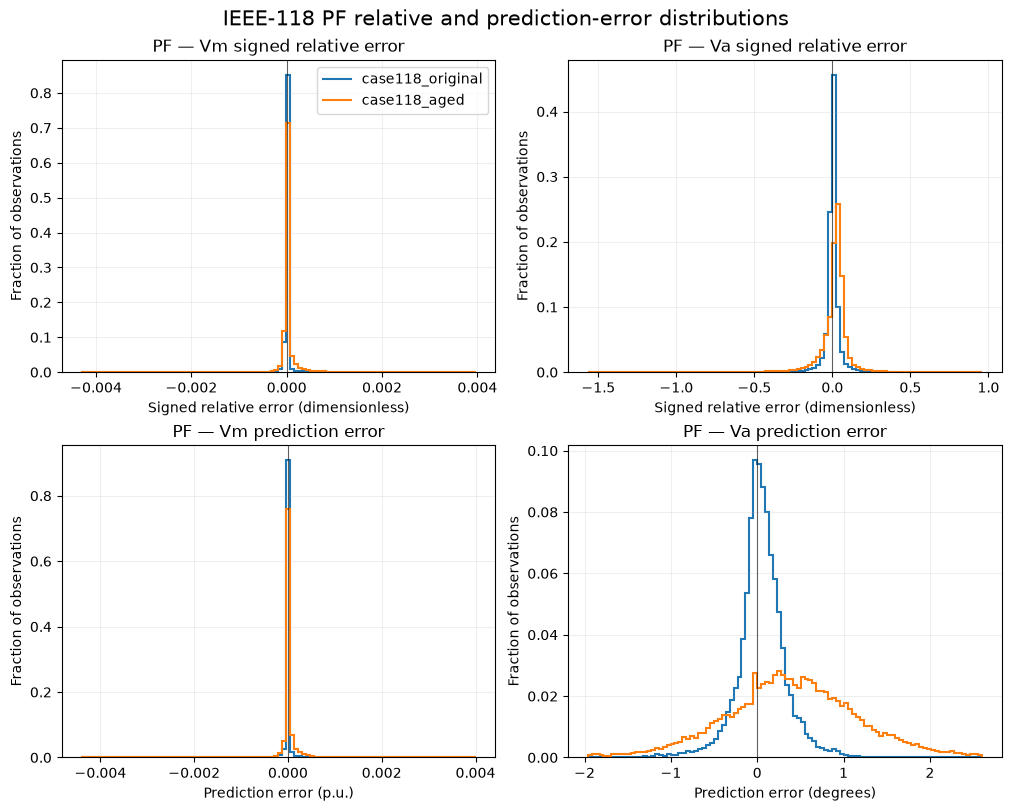

In [10]:
error_specs = {
    "Vm": ("vm_gt_pu", "vm_pred_pu", "p.u."),
    "Va": ("va_gt_deg", "va_pred_deg", "degrees"),
}
RELATIVE_ERROR_EPS = 1e-8


def relative_error(ground_truth, prediction, epsilon=RELATIVE_ERROR_EPS):
    """Return signed relative error, excluding zero and near-zero targets."""
    ground_truth = np.asarray(ground_truth, dtype=np.float64)
    prediction = np.asarray(prediction, dtype=np.float64)
    denominator = np.abs(ground_truth)
    result = np.full(ground_truth.shape, np.nan, dtype=np.float64)
    valid = (
        np.isfinite(ground_truth) & np.isfinite(prediction) & (denominator > epsilon)
    )
    np.divide(prediction - ground_truth, denominator, out=result, where=valid)
    return result


def prediction_error(ground_truth, prediction):
    """Return signed prediction error in the target's original unit."""
    ground_truth = np.asarray(ground_truth, dtype=np.float64)
    prediction = np.asarray(prediction, dtype=np.float64)
    return prediction - ground_truth


def histogram_bins(errors):
    """Build shared bins after checking that each series has finite values."""
    if any(values.size == 0 for values in errors.values()):
        raise ValueError("Cannot plot an error series with no finite values")
    lower = min(np.quantile(values, 0.005) for values in errors.values())
    upper = max(np.quantile(values, 0.995) for values in errors.values())
    if lower == upper:
        lower, upper = lower - 0.5, upper + 0.5
    return np.linspace(lower, upper, 101)


def histogram_fractions(values, bins):
    """Return the fraction of displayed observations in each bin."""
    counts, _ = np.histogram(values, bins=bins)
    displayed_count = counts.sum()
    if displayed_count == 0:
        raise ValueError("No observations fall within the histogram range")
    return counts / displayed_count


plot_rows = (
    ("relative", "Signed relative error"),
    ("prediction", "Prediction error"),
)
colors = {"case118_original": "tab:blue", "case118_aged": "tab:orange"}
fig, axes = plt.subplots(2, 2, figsize=(10, 8), constrained_layout=True)
for col, (variable, (gt_column, pred_column, unit)) in enumerate(error_specs.items()):
    errors_by_kind = {"relative": {}, "prediction": {}}
    for dataset_name in datasets:
        values = pd.read_parquet(
            output_paths[dataset_name],
            columns=[gt_column, pred_column],
        )
        for kind, error in (
            ("relative", relative_error(values[gt_column], values[pred_column])),
            ("prediction", prediction_error(values[gt_column], values[pred_column])),
        ):
            errors_by_kind[kind][dataset_name] = error[np.isfinite(error)]

    for row, (kind, error_label) in enumerate(plot_rows):
        errors = errors_by_kind[kind]
        bins = histogram_bins(errors)
        ax = axes[row, col]
        for dataset_name, error in errors.items():
            fractions = histogram_fractions(error, bins)
            ax.stairs(
                fractions,
                bins,
                label=dataset_name,
                color=colors[dataset_name],
                linewidth=1.5,
            )
        ax.axvline(0, color="black", linewidth=0.8, alpha=0.6)
        x_unit = "dimensionless" if kind == "relative" else unit
        ax.set_xlabel(f"{error_label} ({x_unit})")
        ax.set_ylabel("Fraction of observations")
        ax.grid(alpha=0.2)
        if row == 0 and col == 0:
            ax.legend()

histogram_path = OUTPUT_DIR / "error_histograms.pdf"
fig.savefig(histogram_path, dpi=300, bbox_inches="tight")
print(f"Saved histogram to {histogram_path}")
plt.show()

## 6. Hidden-aging experiment: aged state with original line impedance

This experiment represents an aged physical network whose changed line impedances are unknown to the operator. Bus/generator measurements, branch flows, and all ground-truth targets come from `case118_aged`, while the model receives the matched original network's line-admittance features. Graphkit does not feed raw `r` and `x` to the model; their effect is encoded by the four directional admittance columns `Yff`/`Yft` (and `Ytt`/`Ytf` on reverse edges), so only those normalized columns are replaced. Branch status, topology, limits, tap settings, and every measured or target quantity remain from the aged case.

Cases are paired by load-scenario ID and scenario signature (active branches/generators plus the randomized generator costs), rather than by dataset row number. Aged cases with no exact original counterpart are excluded and reported below. The final histogram compares signed relative errors and signed prediction errors for the correctly specified aged run and hidden-aging run on exactly the same retained scenarios.


In [11]:
ORIGINAL_NAME = "case118_original"
AGED_NAME = "case118_aged"
HIDDEN_AGING_NAME = "case118_aged_original_impedance"
original_dataset = datasets[ORIGINAL_NAME]
aged_dataset = datasets[AGED_NAME]
edge_type = ("bus", "connects", "bus")
admittance_columns = slice(YFF_TT_R, YFT_TF_I + 1)


def group_indices_by_load(dataset):
    groups = {}
    for index, load_index in enumerate(dataset.load_scenarios.tolist()):
        groups.setdefault(int(load_index), []).append(index)
    return groups


def scenario_signature(graph):
    branch_on = (graph[edge_type].edge_attr[:, B_ON] > 0.5).to(torch.uint8)
    generator_on = (graph["gen"].x[:, G_ON] > 0.5).to(torch.uint8)
    generator_cost = graph["gen"].x[:, C0_H : C2_H + 1]
    return (
        branch_on.cpu().numpy().tobytes(),
        generator_on.cpu().numpy().tobytes(),
        generator_cost.cpu().numpy().tobytes(),
    )


original_groups = group_indices_by_load(original_dataset)
aged_groups = group_indices_by_load(aged_dataset)
hidden_aging_pairs = {}


def match_in_order(aged_indices, original_indices):
    """Return the longest order-preserving match of scenario signatures."""
    aged_signatures = [scenario_signature(aged_dataset[i]) for i in aged_indices]
    original_signatures = [
        scenario_signature(original_dataset[i]) for i in original_indices
    ]
    n_aged, n_original = len(aged_indices), len(original_indices)
    lengths = np.zeros((n_aged + 1, n_original + 1), dtype=np.int8)
    for i in range(n_aged):
        for j in range(n_original):
            if aged_signatures[i] == original_signatures[j]:
                lengths[i + 1, j + 1] = lengths[i, j] + 1
            else:
                lengths[i + 1, j + 1] = max(lengths[i, j + 1], lengths[i + 1, j])
    pairs = {}
    i, j = n_aged, n_original
    while i and j:
        if aged_signatures[i - 1] == original_signatures[j - 1]:
            pairs[aged_indices[i - 1]] = original_indices[j - 1]
            i -= 1
            j -= 1
        elif lengths[i - 1, j] >= lengths[i, j - 1]:
            i -= 1
        else:
            j -= 1
    return pairs


for load_index, aged_indices in aged_groups.items():
    original_indices = original_groups.get(load_index, [])
    hidden_aging_pairs.update(match_in_order(aged_indices, original_indices))

hidden_aging_indices = sorted(hidden_aging_pairs)
excluded_count = len(aged_dataset) - len(hidden_aging_indices)
print(f"Matched {len(hidden_aging_indices):,} aged scenarios")
print(f"Excluded {excluded_count:,} aged scenarios without an original counterpart")

Matched 1,000 aged scenarios
Excluded 0 aged scenarios without an original counterpart


In [12]:
def prepare_hidden_aging_graph(dataset, aged_index):
    aged_graph = dataset[aged_index]
    original_index = hidden_aging_pairs[aged_index]
    original_graph = original_dataset[original_index]

    if not torch.equal(
        aged_graph[edge_type].edge_index, original_graph[edge_type].edge_index
    ):
        raise ValueError(f"Edge ordering differs for aged scenario {aged_index}")
    if scenario_signature(aged_graph) != scenario_signature(original_graph):
        raise ValueError(f"Scenario pairing differs for aged scenario {aged_index}")
    if not np.isclose(float(aged_graph.baseMVA), float(original_graph.baseMVA)):
        raise ValueError(f"baseMVA differs for aged scenario {aged_index}")

    # Both graphs are already normalized with the same saved normalizer.
    # Replace only the impedance-derived model inputs; retain all aged targets.
    aged_graph[edge_type].edge_attr[:, admittance_columns] = original_graph[
        edge_type
    ].edge_attr[:, admittance_columns]
    return pf_transform(aged_graph)


output_path = OUTPUT_DIR / f"{HIDDEN_AGING_NAME}_pf_ground_truth_predictions.parquet"
if output_path.exists():
    print(f"Reusing existing output: {output_path}")
else:
    output_path = predict_all(
        HIDDEN_AGING_NAME,
        aged_dataset,
        indices=hidden_aging_indices,
        graph_preparer=prepare_hidden_aging_graph,
    )
output_paths[HIDDEN_AGING_NAME] = output_path
print(f"Successfully evaluated {len(hidden_aging_indices):,} matched scenarios")

Reusing existing output: results/local_predictions/case118_aged_original_impedance_pf_ground_truth_predictions.parquet
Successfully evaluated 1,000 matched scenarios


Saved histogram to results/local_predictions/hidden_aging_error_histograms.png


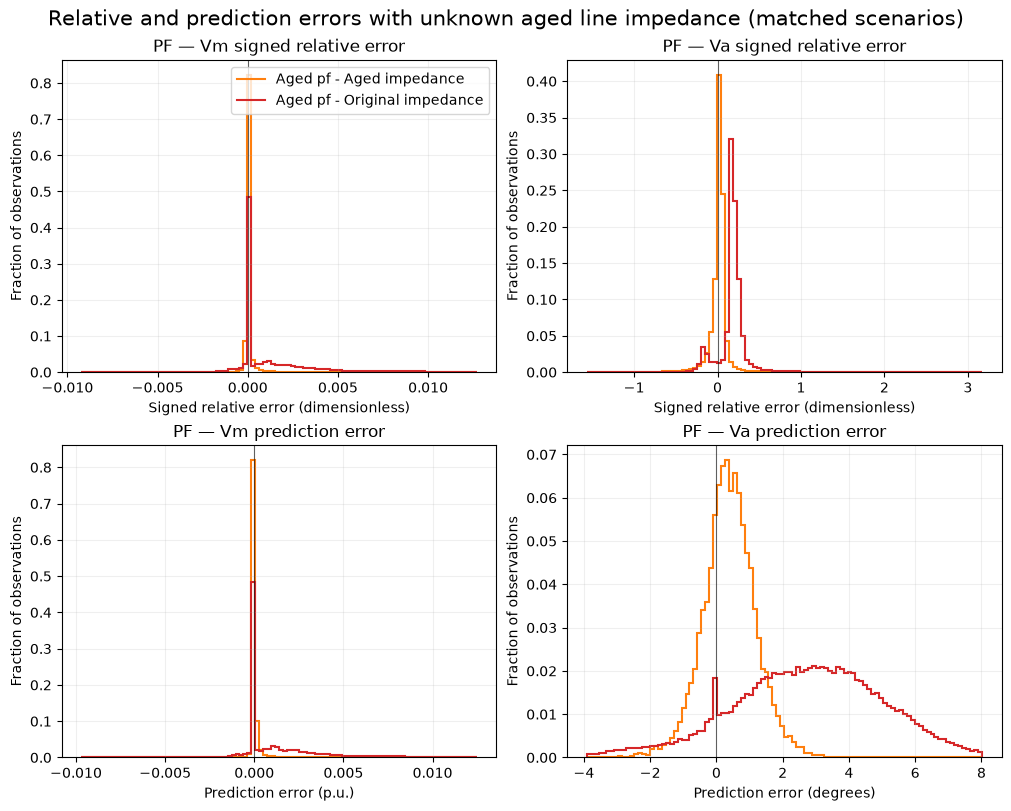

In [13]:
comparison_colors = {
    "Aged pf - Aged impedance": "tab:orange",
    "Aged pf - Original impedance": "tab:red",
}
fig, axes = plt.subplots(2, 2, figsize=(10, 8), constrained_layout=True)
retained_indices = set(hidden_aging_indices)

for col, (variable, (gt_column, pred_column, unit)) in enumerate(error_specs.items()):
    columns = key_columns + [gt_column, pred_column]
    aged_known = pd.read_parquet(output_paths[AGED_NAME], columns=columns)
    aged_known = aged_known[aged_known["dataset_index"].isin(retained_indices)]
    aged_hidden = pd.read_parquet(output_paths[HIDDEN_AGING_NAME], columns=columns)
    aged_known = aged_known.reset_index(drop=True)
    aged_hidden = aged_hidden.reset_index(drop=True)
    if not aged_known[key_columns].equals(aged_hidden[key_columns]):
        raise ValueError(f"Comparison row keys differ for PF {variable}")
    if not np.allclose(aged_known[gt_column], aged_hidden[gt_column]):
        raise ValueError(f"Ground truths differ for PF {variable}")

    errors_by_kind = {
        "relative": {
            "Aged pf - Aged impedance": relative_error(
                aged_known[gt_column], aged_known[pred_column]
            ),
            "Aged pf - Original impedance": relative_error(
                aged_hidden[gt_column], aged_hidden[pred_column]
            ),
        },
        "prediction": {
            "Aged pf - Aged impedance": prediction_error(
                aged_known[gt_column], aged_known[pred_column]
            ),
            "Aged pf - Original impedance": prediction_error(
                aged_hidden[gt_column], aged_hidden[pred_column]
            ),
        },
    }
    for row, (kind, error_label) in enumerate(plot_rows):
        errors = {
            name: values[np.isfinite(values)]
            for name, values in errors_by_kind[kind].items()
        }
        bins = histogram_bins(errors)
        ax = axes[row, col]
        for name, error in errors.items():
            fractions = histogram_fractions(error, bins)
            ax.stairs(
                fractions,
                bins,
                label=name,
                color=comparison_colors[name],
                linewidth=1.5,
            )
        ax.axvline(0, color="black", linewidth=0.8, alpha=0.6)
        x_unit = "dimensionless" if kind == "relative" else unit
        ax.set_xlabel(f"{error_label} ({x_unit})")
        ax.set_ylabel("Fraction of observations")
        ax.grid(alpha=0.2)
        if row == 0 and col == 0:
            ax.legend(loc="upper right")

hidden_histogram_path = OUTPUT_DIR / "hidden_aging_error_histograms.pdf"
fig.savefig(hidden_histogram_path, dpi=300, bbox_inches="tight")
print(f"Saved histogram to {hidden_histogram_path}")
plt.show()

## 7. Use GENCO to improve the estimate of the aged lines

A well known method of noise suppression of the sample is to use gradient-based denoising. Our prior is that our input line impedance are noisy because of aging of the lines. This phenomena caused a shift/drift in network's line impedance, and it corrupted our admittance matrix. Now, I want to try to recover/retrieve the shifted Y-matrix, using the GENCO model. I want to fix the model parameters, back propagate the error, and shift the inputs for a little bit each time in a direction that minimizes the GENCO model error. This process should be done over lots of samples of the data we collected using aged line impedances.

The code below assumes the aged Y-matrix is unknown but an estimate of the original impedance exists. It optimizes dimensionless R/X multipliers instead of raw per-unit values, accumulates an exact full-dataset mean gradient, and takes one projected Adam step per epoch. Multipliers are bounded by the same 1.0--1.5 range used to generate the synthetic ageing, which prevents low-impedance lines from dominating the update.

During the iterative denoising process, plot the these quantities using tensorboard in a folder named `tb`:

1- impedance mismatch = actual aged line impedance - current estimated line impedance (diagnostic only)

2- model RMSE = error on the checkpoint's masked Vm/Va reconstruction target using the current line impedance


In [14]:
import re
from datetime import datetime

from torch.nn import functional as F

from torch.utils.tensorboard import SummaryWriter

# Optimize physical line resistance/reactance over every available aged scenario.
EPOCHS = 250
LR = 3e-3
MULTIPLIER_MIN = 1.0
MULTIPLIER_MAX = 1.5
TB_RUN_NAME = datetime.now().strftime("impedance-multiplier-denoising-%Y%m%d-%H%M%S")
TB_DIR = PROJECT_DIR / "tb" / TB_RUN_NAME
DENOISED_Y_PATH = OUTPUT_DIR / "denoised_admittance.pt"


def available_dataset_indices(dataset):
    """Return actual saved scenario IDs, including datasets with solver gaps."""
    prefix = "data_index_"
    return sorted(
        int(path.stem.removeprefix(prefix))
        for path in Path(dataset.processed_dir).glob(f"{prefix}*.pt")
    )


training_indices = available_dataset_indices(aged_dataset)
original_training_indices = available_dataset_indices(original_dataset)
if not training_indices:
    raise RuntimeError("The aged dataset contains no scenarios")
if not original_training_indices:
    raise RuntimeError("The original dataset contains no scenarios")

# Every untransformed scenario has the same complete directed-edge ordering. The
# first half stores from->to edges and the second half their to->from counterparts.
reference_graph = aged_dataset.get(training_indices[0])
reference_edge_index = reference_graph[edge_type].edge_index.clone()
n_directed_edges = reference_edge_index.size(1)
n_lines = n_directed_edges // 2
if not torch.equal(
    reference_edge_index[:, :n_lines],
    reference_edge_index.flip(0)[:, n_lines:],
):
    raise ValueError("Forward and reverse branch ordering is not aligned")


def mean_admittance(dataset, indices, description):
    """Average Y only while each directed branch is in service."""
    total = torch.zeros((n_directed_edges, 4), dtype=torch.float64)
    total_squared = torch.zeros_like(total)
    active_count = torch.zeros(n_directed_edges, dtype=torch.float64)
    for index in tqdm(indices, desc=description):
        graph = dataset.get(index)
        if not torch.equal(graph[edge_type].edge_index, reference_edge_index):
            raise ValueError(f"Full edge ordering differs for dataset index {index}")
        edge_attr = graph[edge_type].edge_attr
        values = edge_attr[:, admittance_columns].double()
        active = edge_attr[:, B_ON] > 0.5
        total[active] += values[active]
        total_squared[active] += values[active].square()
        active_count[active] += 1
    if (active_count == 0).any():
        missing = (active_count == 0).nonzero(as_tuple=False).flatten().tolist()
        raise RuntimeError(f"Directed branches never observed in service: {missing}")
    mean = total / active_count[:, None]
    variance = (total_squared / active_count[:, None] - mean.square()).clamp_min(0)
    return mean.float(), variance.sqrt().float()


# Average only active observations. shape: 372 x 4 (Yff_r, Yff_i, Yft_r, Yft_i)
initial_admittance, original_admittance_std = mean_admittance(
    original_dataset,
    original_training_indices,
    "Averaging original Y",
)
actual_aged_admittance, aged_admittance_std = mean_admittance(
    aged_dataset,
    training_indices,
    "Averaging aged Y (diagnostic only)",
)

# Datakit normalizes Y by baseMVA_orig/baseMVA. For an ordinary line,
# Ytf = Yft = -1/(R+jX), so R+jX = scale/(-Yft_normalized).
admittance_scale = float(normalizer.baseMVA_orig / normalizer.baseMVA)
# initial_[self|cross]_[forward|reverse] shape: 186 x 1 (complex)
initial_self_forward = torch.complex(
    initial_admittance[:n_lines, 0],
    initial_admittance[:n_lines, 1],
)
initial_cross_forward = torch.complex(
    initial_admittance[:n_lines, 2],
    initial_admittance[:n_lines, 3],
)
initial_self_reverse = torch.complex(
    initial_admittance[n_lines:, 0],
    initial_admittance[n_lines:, 1],
)
initial_cross_reverse = torch.complex(
    initial_admittance[n_lines:, 2],
    initial_admittance[n_lines:, 3],
)
initial_series_y = -initial_cross_forward
initial_impedance = admittance_scale / initial_series_y
forward_shunt = initial_self_forward - initial_series_y
reverse_shunt = initial_self_reverse - initial_series_y

# Read the original MATPOWER branch metadata to identify learnable lines:
# estimate ageing-related R/X changes only for  branches.
original_case_path = PROJECT_DIR / "grids" / "case118_original.m"
original_case_text = original_case_path.read_text()
branch_match = re.search(
    r"mpc\.branch\s*=\s*\[(.*?)\];",
    original_case_text,
    re.DOTALL,
)

# Mark the branch as learnable only if it is in service and is not represented as a transformer.
branch_fields = []
for line in branch_match.group(1).splitlines():
    fields = line.partition("%")[0].strip().rstrip(";").split()
    if fields:
        branch_fields.append(fields)
learnable_line_mask = torch.tensor(
    [
        float(fields[10]) > 0
        and not (
            (float(fields[8]) != 0.0 and float(fields[8]) != 1.0)
            or float(fields[9]) != 0.0
        )
        for fields in branch_fields
    ],
    dtype=torch.bool,
)
# duplicate for from bus and to bus
learnable_directed_mask = torch.cat([learnable_line_mask, learnable_line_mask])

initial_resistance = initial_impedance.real.float()
initial_reactance = initial_impedance.imag.float()
resistance_multiplier = torch.nn.Parameter(torch.ones_like(initial_resistance))
reactance_multiplier = torch.nn.Parameter(torch.ones_like(initial_reactance))
multiplier_parameters = [resistance_multiplier, reactance_multiplier]
optimizer = torch.optim.Adam(multiplier_parameters, lr=LR)


def estimated_impedance_components():
    """Map dimensionless ageing multipliers to per-unit R/X."""
    return (
        initial_resistance * resistance_multiplier,
        initial_reactance * reactance_multiplier,
    )


def impedance_from_admittance(admittance):
    """Recover ordinary-line R/X from normalized forward transfer admittance."""
    cross = torch.complex(admittance[:n_lines, 2], admittance[:n_lines, 3])
    return admittance_scale / (-cross)


actual_aged_impedance = impedance_from_admittance(actual_aged_admittance)
actual_aged_resistance = actual_aged_impedance.real
actual_aged_reactance = actual_aged_impedance.imag


def admittance_from_estimated_impedance():
    """Differentiably convert bounded R/X multipliers to normalized Y inputs."""
    estimated_resistance, estimated_reactance = estimated_impedance_components()
    impedance = torch.complex(estimated_resistance, estimated_reactance)
    series_y = admittance_scale / impedance
    estimated = initial_admittance.clone()

    forward_values = torch.stack(
        [
            (series_y + forward_shunt).real,
            (series_y + forward_shunt).imag,
            -series_y.real,
            -series_y.imag,
        ],
        dim=1,
    )
    reverse_values = torch.stack(
        [
            (series_y + reverse_shunt).real,
            (series_y + reverse_shunt).imag,
            -series_y.real,
            -series_y.imag,
        ],
        dim=1,
    )
    estimated[:n_lines][learnable_line_mask] = forward_values[learnable_line_mask]
    estimated[n_lines:][learnable_line_mask] = reverse_values[learnable_line_mask]
    return estimated


# Freeze GENCO. Gradients pass through it to R/X, but model weights never update.
model.eval()
for parameter in model.parameters():
    parameter.requires_grad_(False)


def prepare_denoising_graph(aged_index, estimated_admittance):
    """Insert the shared estimated line Y values into graph, then apply the standard PF mask."""
    graph = aged_dataset[aged_index]
    edge_attr = graph[edge_type].edge_attr.clone()
    current_y = edge_attr[:, admittance_columns].clone()
    current_y[learnable_directed_mask] = estimated_admittance[learnable_directed_mask]
    edge_attr[:, admittance_columns] = current_y
    graph[edge_type].edge_attr = edge_attr
    return pf_transform(graph)


def masked_pf_model_loss(batch, output):
    """The checkpoint's MaskedBusMSE: masked Vm/Va in normalized space."""
    target = batch["bus"].y[:, [VM_H, VA_H]]
    prediction = output["bus"][:, [VM_OUT, VA_OUT]]
    supervised_mask = batch.mask_dict["bus"][:, [VM_H, VA_H]]
    target_count = int(supervised_mask.sum().item())
    return (
        F.mse_loss(prediction[supervised_mask], target[supervised_mask]),
        target_count,
    )


def evaluate_model_mse(indices, description):
    """Evaluate one fixed R/X state over all requested scenarios."""
    loss_sum = 0.0
    target_count = 0
    with torch.no_grad():
        for start in tqdm(
            range(0, len(indices), BATCH_SIZE),
            desc=description,
            leave=False,
        ):
            batch_indices = indices[start : start + BATCH_SIZE]
            current_admittance = admittance_from_estimated_impedance()
            graphs = [
                prepare_denoising_graph(index, current_admittance)
                for index in batch_indices
            ]
            batch = Batch.from_data_list(graphs).to(DEVICE)
            model_loss, batch_target_count = masked_pf_model_loss(batch, model(batch))
            loss_sum += model_loss.item() * batch_target_count
            target_count += batch_target_count
    return loss_sum / target_count


def impedance_metrics():
    """Return diagnostic errors without exposing aged Y to optimization."""
    estimated_resistance, estimated_reactance = estimated_impedance_components()
    resistance_mismatch = actual_aged_resistance - estimated_resistance.detach()
    resistance_mismatch = resistance_mismatch[learnable_line_mask]
    reactance_mismatch = actual_aged_reactance - estimated_reactance.detach()
    reactance_mismatch = reactance_mismatch[learnable_line_mask]
    combined = torch.cat([resistance_mismatch, reactance_mismatch])
    return resistance_mismatch, reactance_mismatch, combined


def log_epoch_metrics(writer, step, model_mse, gradient_norms=None):
    resistance_mismatch, reactance_mismatch, combined = impedance_metrics()
    resistance_values = resistance_multiplier.detach()[learnable_line_mask]
    reactance_values = reactance_multiplier.detach()[learnable_line_mask]
    mismatch_mae = combined.abs().mean().item()
    mismatch_rmse = combined.square().mean().sqrt().item()
    model_rmse = model_mse**0.5
    writer.add_scalar("epoch/model_rmse", model_rmse, step)
    writer.add_scalar("epoch/impedance_mismatch_mae", mismatch_mae, step)
    writer.add_scalar("epoch/impedance_mismatch_rmse", mismatch_rmse, step)
    writer.add_scalar(
        "epoch/resistance_mismatch_rmse",
        resistance_mismatch.square().mean().sqrt().item(),
        step,
    )
    writer.add_scalar(
        "epoch/reactance_mismatch_rmse",
        reactance_mismatch.square().mean().sqrt().item(),
        step,
    )
    writer.add_histogram("epoch/resistance_mismatch", resistance_mismatch, step)
    writer.add_histogram("epoch/reactance_mismatch", reactance_mismatch, step)
    writer.add_scalar("epoch/learning_rate", optimizer.param_groups[0]["lr"], step)
    if gradient_norms is not None:
        writer.add_scalar(
            "epoch/gradient_norm",
            float(np.linalg.norm(gradient_norms)),
            step,
        )
    writer.flush()
    return (
        model_rmse,
        mismatch_mae,
        mismatch_rmse,
        resistance_values.median().item(),
        reactance_values.median().item(),
        resistance_values.max().item(),
        reactance_values.max().item(),
    )

Averaging original Y:   0%|          | 0/1000 [00:00<?, ?it/s]

Averaging aged Y (diagnostic only):   0%|          | 0/1000 [00:00<?, ?it/s]

In [15]:
# HERE

In [16]:
writer = SummaryWriter(log_dir=str(TB_DIR))
last_model_mse = None
for epoch in range(EPOCHS):
    epoch_generator = torch.Generator().manual_seed(SEED + epoch)
    order = torch.randperm(
        len(training_indices),
        generator=epoch_generator,
    )
    order = order.tolist()
    epoch_loss_sum = 0.0
    epoch_target_count = 0
    optimizer.zero_grad()

    progress = tqdm(
        range(0, len(order), BATCH_SIZE),
        desc=f"Multiplier R/X epoch {epoch + 1}/{EPOCHS}",
        leave=False,
    )
    for start in progress:
        positions = order[start : start + BATCH_SIZE]
        batch_indices = [training_indices[position] for position in positions]
        current_admittance = admittance_from_estimated_impedance()
        graphs = [
            prepare_denoising_graph(index, current_admittance)
            for index in batch_indices
        ]
        # torchgemoetric.data.Batch:
        # A data object describing a batch of graphs as one big (disconnected) graph.
        batch = Batch.from_data_list(graphs).to(DEVICE)

        output = model(batch)
        model_loss, target_count = masked_pf_model_loss(batch, output)
        # Accumulate the exact full-dataset mean gradient. Stepping here would
        # apply LR once per mini-batch and make the result batch-size dependent.
        (model_loss * target_count).backward()

        epoch_loss_sum += model_loss.item() * target_count
        epoch_target_count += target_count
        progress.set_postfix(model_rmse=f"{model_loss.item() ** 0.5:.3e}")

    epoch_model_mse = epoch_loss_sum / epoch_target_count
    gradient_norms = []
    for parameter in multiplier_parameters:
        parameter.grad.div_(epoch_target_count)
        parameter.grad[~learnable_line_mask] = 0.0
        if not torch.isfinite(parameter.grad).all():
            raise RuntimeError("Non-finite R/X multiplier gradient")
        gradient_norms.append(parameter.grad[learnable_line_mask].norm().item())
    if epoch == 0:
        log_epoch_metrics(writer, 0, epoch_model_mse)

    optimizer.step()
    with torch.no_grad():
        for parameter in multiplier_parameters:
            parameter.clamp_(MULTIPLIER_MIN, MULTIPLIER_MAX)
            parameter[~learnable_line_mask] = 1.0

    candidate_mse = evaluate_model_mse(
        training_indices,
        f"Checking multiplier epoch {epoch + 1}",
    )
    last_model_mse = candidate_mse
    (
        model_rmse,
        mismatch_mae,
        mismatch_rmse,
        resistance_median,
        reactance_median,
        resistance_max,
        reactance_max,
    ) = log_epoch_metrics(writer, epoch + 1, candidate_mse, gradient_norms)
    # print(
    #     f"Epoch {epoch + 1:02d}: model RMSE={model_rmse:.6e}, "
    #     f"R/X mismatch MAE={mismatch_mae:.6e}, "
    #     f"R/X mismatch RMSE={mismatch_rmse:.6e}, "
    #     f"median multipliers=({resistance_median:.4f}, {reactance_median:.4f}), "
    #     f"max multipliers=({resistance_max:.4f}, {reactance_max:.4f})"
    # )
writer.close()

estimated_resistance, estimated_reactance = estimated_impedance_components()
final_admittance = admittance_from_estimated_impedance().detach().cpu()
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
torch.save(
    {
        "edge_index": reference_edge_index,
        "learnable_line_mask": learnable_line_mask,
        "estimated_resistance_pu": estimated_resistance.detach().cpu(),
        "estimated_reactance_pu": estimated_reactance.detach().cpu(),
        "estimated_resistance_multiplier": resistance_multiplier.detach().cpu(),
        "estimated_reactance_multiplier": reactance_multiplier.detach().cpu(),
        "initial_resistance_pu": initial_resistance,
        "initial_reactance_pu": initial_reactance,
        "actual_aged_resistance_pu": actual_aged_resistance,
        "actual_aged_reactance_pu": actual_aged_reactance,
        "estimated_admittance_normalized": final_admittance,
        "initial_admittance_normalized": initial_admittance,
        "actual_aged_admittance_normalized": actual_aged_admittance,
        "original_scenario_std": original_admittance_std,
        "aged_scenario_std": aged_admittance_std,
        "training_indices": torch.as_tensor(training_indices),
        "epochs": EPOCHS,
        "learning_rate": LR,
        "optimizer": "Adam",
        "multiplier_bounds": (MULTIPLIER_MIN, MULTIPLIER_MAX),
        "constraint": "R and X are initial values times bounded ageing multipliers",
    },
    DENOISED_Y_PATH,
)
print(f"Optimized {int(learnable_line_mask.sum()):,} non-transformer lines")
print(f"Saved bounded multiplier-space R/X and recovered Y to {DENOISED_Y_PATH}")
print(f"TensorBoard logs: {TB_DIR}")
print(f"Launch with: tensorboard --logdir {TB_DIR}")

Multiplier R/X epoch 1/250:   0%|          | 0/63 [00:00<?, ?it/s]

Checking multiplier epoch 1:   0%|          | 0/63 [00:00<?, ?it/s]

Multiplier R/X epoch 2/250:   0%|          | 0/63 [00:00<?, ?it/s]

Checking multiplier epoch 2:   0%|          | 0/63 [00:00<?, ?it/s]

Multiplier R/X epoch 3/250:   0%|          | 0/63 [00:00<?, ?it/s]

...

Multiplier R/X epoch 249/250:   0%|          | 0/63 [00:00<?, ?it/s]

Checking multiplier epoch 249:   0%|          | 0/63 [00:00<?, ?it/s]

Multiplier R/X epoch 250/250:   0%|          | 0/63 [00:00<?, ?it/s]

Checking multiplier epoch 250:   0%|          | 0/63 [00:00<?, ?it/s]

Optimized 177 non-transformer lines
Saved bounded multiplier-space R/X and recovered Y to results/local_predictions/denoised_admittance.pt
TensorBoard logs: tb/impedance-multiplier-denoising-20261022-180641
Launch with: tensorboard --logdir tb/impedance-multiplier-denoising-20261022-180641


Saved plot to results/local_predictions/resistance_comparison.png


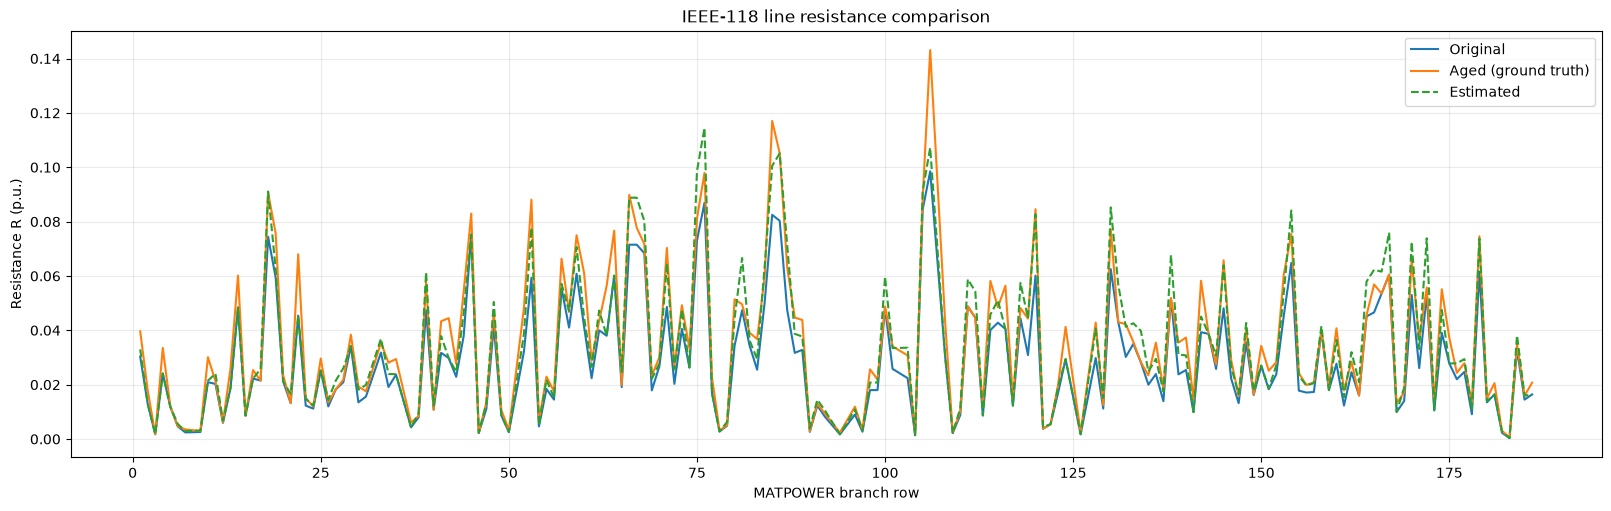

Saved plot to results/local_predictions/reactance_comparison.png


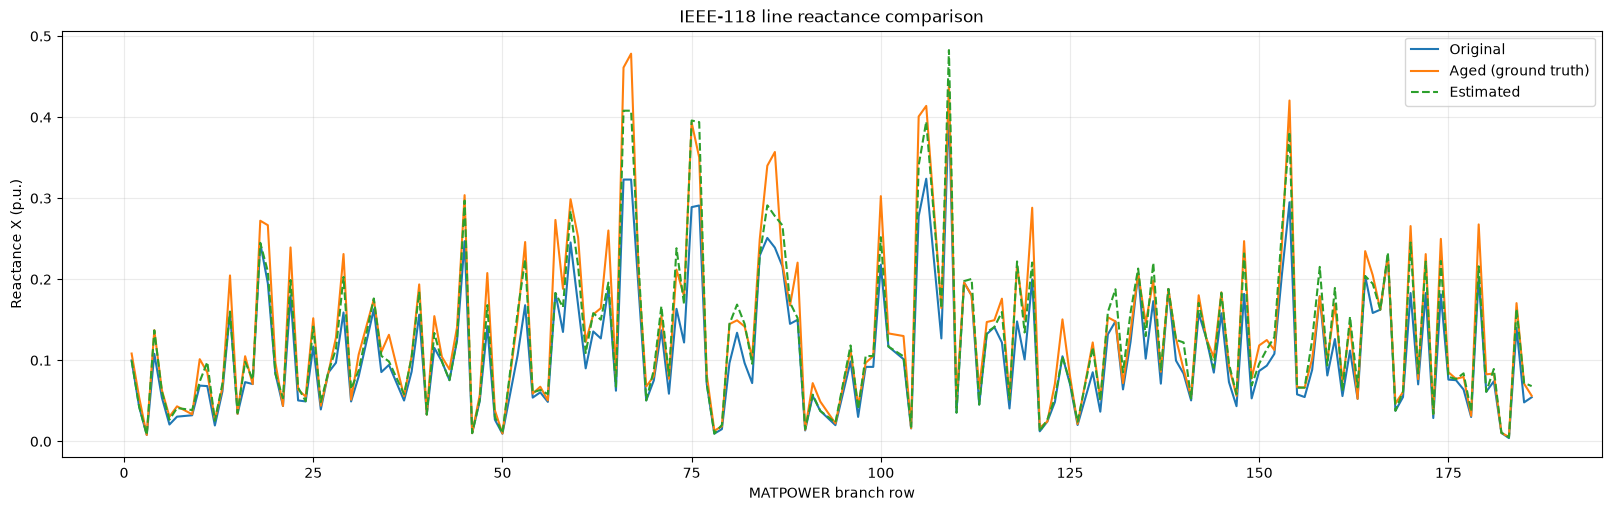

In [17]:
# Compare the original, true aged, and GENCO-estimated line impedances.
impedance_result = torch.load(
    DENOISED_Y_PATH,
    map_location="cpu",
    weights_only=True,
)
plot_mask = impedance_result["learnable_line_mask"].bool()
branch_rows = torch.arange(1, plot_mask.numel() + 1)[plot_mask].numpy()


def plot_impedance_component(component, ylabel, output_name):
    original = impedance_result[f"initial_{component}_pu"][plot_mask].numpy()
    aged = impedance_result[f"actual_aged_{component}_pu"][plot_mask].numpy()
    estimated = impedance_result[f"estimated_{component}_pu"][plot_mask].numpy()

    fig, ax = plt.subplots(figsize=(16, 5), constrained_layout=True)
    ax.plot(branch_rows, original, label="Original", color="tab:blue", linewidth=1.5)
    ax.plot(
        branch_rows,
        aged,
        label="Aged (ground truth)",
        color="tab:orange",
        linewidth=1.5,
    )
    ax.plot(
        branch_rows,
        estimated,
        label="Estimated",
        color="tab:green",
        linewidth=1.5,
        linestyle="--",
    )
    ax.set_xlabel("MATPOWER branch row")
    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.25)
    ax.legend()

    output_path = OUTPUT_DIR / output_name
    fig.savefig(output_path, dpi=300, bbox_inches="tight")
    print(f"Saved plot to {output_path}")
    plt.show()


plot_impedance_component(
    "resistance",
    "Resistance R (p.u.)",
    "resistance_comparison.pdf",
)
plot_impedance_component(
    "reactance",
    "Reactance X (p.u.)",
    "reactance_comparison.pdf",
)

Saved parity plot to results/local_predictions/resistance_estimated_vs_aged.png


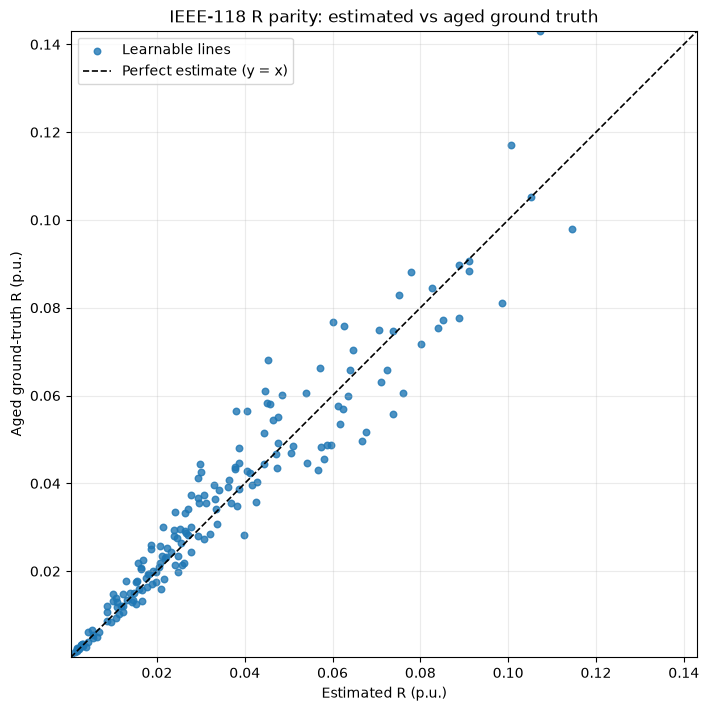

Saved parity plot to results/local_predictions/reactance_estimated_vs_aged.png


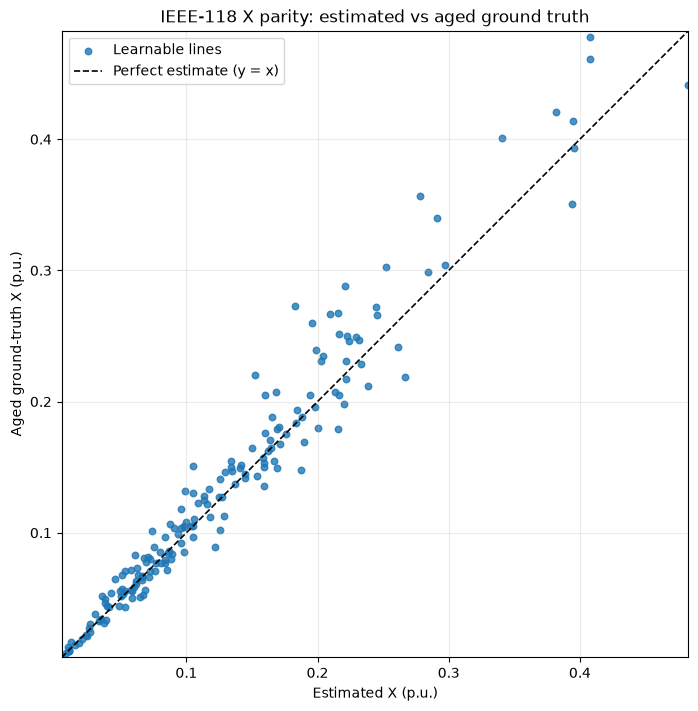

In [18]:
# Parity plots compare estimated impedance against the aged ground truth.
def plot_impedance_parity(component, symbol, output_name):
    aged = impedance_result[f"actual_aged_{component}_pu"][plot_mask].numpy()
    estimated = impedance_result[f"estimated_{component}_pu"][plot_mask].numpy()
    valid = np.isfinite(aged) & np.isfinite(estimated)
    if not valid.any():
        raise ValueError(f"No valid {symbol} values are available to plot")

    aged = aged[valid]
    estimated = estimated[valid]
    lower = min(aged.min(), estimated.min())
    upper = max(aged.max(), estimated.max())
    if lower == upper:
        padding = max(abs(lower) * 0.05, 1e-12)
        lower -= padding
        upper += padding

    fig, ax = plt.subplots(figsize=(7, 7), constrained_layout=True)
    ax.scatter(
        estimated,
        aged,
        s=22,
        color="tab:blue",
        alpha=0.8,
        label="Learnable lines",
    )
    ax.plot(
        [lower, upper],
        [lower, upper],
        color="black",
        linestyle="--",
        linewidth=1.2,
        label="Perfect estimate (y = x)",
    )
    ax.set_xlim(lower, upper)
    ax.set_ylim(lower, upper)
    ax.set_aspect("equal", adjustable="box")
    ax.set_xlabel(f"Estimated {symbol} (p.u.)")
    ax.set_ylabel(f"Aged ground-truth {symbol} (p.u.)")
    ax.grid(alpha=0.25)
    ax.legend()

    output_path = OUTPUT_DIR / output_name
    fig.savefig(output_path, dpi=300, bbox_inches="tight")
    print(f"Saved parity plot to {output_path}")
    plt.show()


plot_impedance_parity(
    "resistance",
    "R",
    "resistance_estimated_vs_aged.pdf",
)
plot_impedance_parity(
    "reactance",
    "X",
    "reactance_estimated_vs_aged.pdf",
)

Saved normalized-residual plot to results/local_predictions/resistance_relative_residual_vs_ground_truth.png


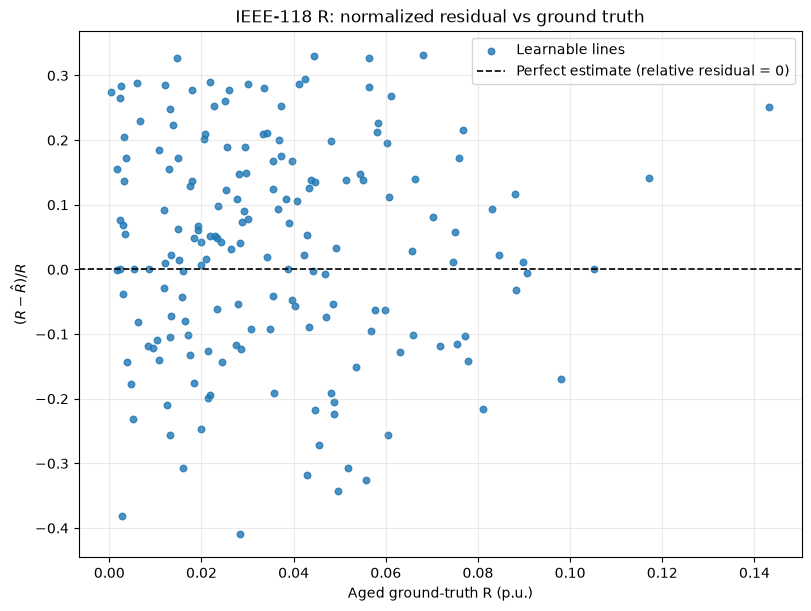

Saved normalized-residual plot to results/local_predictions/reactance_relative_residual_vs_ground_truth.png


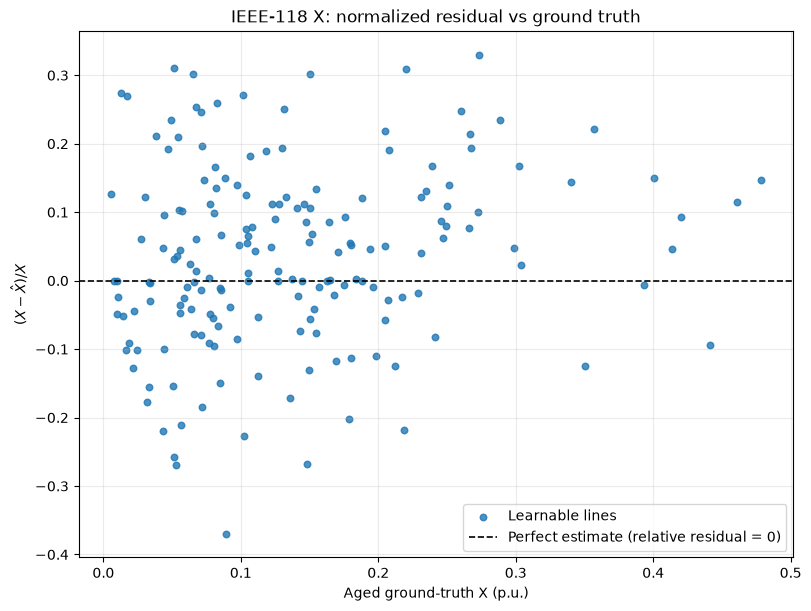

In [19]:
# Plot normalized impedance residuals against the aged ground truth.
IMPEDANCE_DENOMINATOR_EPS = 1e-12


def plot_impedance_relative_residual(component, symbol, output_name):
    aged = impedance_result[f"actual_aged_{component}_pu"][plot_mask].numpy()
    estimated = impedance_result[f"estimated_{component}_pu"][plot_mask].numpy()
    valid = (
        np.isfinite(aged)
        & np.isfinite(estimated)
        & (np.abs(aged) > IMPEDANCE_DENOMINATOR_EPS)
    )
    if not valid.any():
        raise ValueError(f"No valid nonzero {symbol} values are available to plot")

    aged = aged[valid]
    estimated = estimated[valid]
    relative_residual = (aged - estimated) / aged

    fig, ax = plt.subplots(figsize=(8, 6), constrained_layout=True)
    ax.scatter(
        aged,
        relative_residual,
        s=22,
        color="tab:blue",
        alpha=0.8,
        label="Learnable lines",
    )
    ax.axhline(
        0.0,
        color="black",
        linestyle="--",
        linewidth=1.2,
        label="Perfect estimate (relative residual = 0)",
    )
    ax.set_xlabel(f"Aged ground-truth {symbol} (p.u.)")
    ax.set_ylabel(rf"$({symbol} - \hat{{{symbol}}}) / {symbol}$")
    ax.grid(alpha=0.25)
    ax.legend()

    output_path = OUTPUT_DIR / output_name
    fig.savefig(output_path, dpi=300, bbox_inches="tight")
    print(f"Saved normalized-residual plot to {output_path}")
    plt.show()


plot_impedance_relative_residual(
    "resistance",
    "R",
    "resistance_relative_residual_vs_ground_truth.pdf",
)
plot_impedance_relative_residual(
    "reactance",
    "X",
    "reactance_relative_residual_vs_ground_truth.pdf",
)

Saved error-distribution plot to results/local_predictions/impedance_relative_error_distributions.png


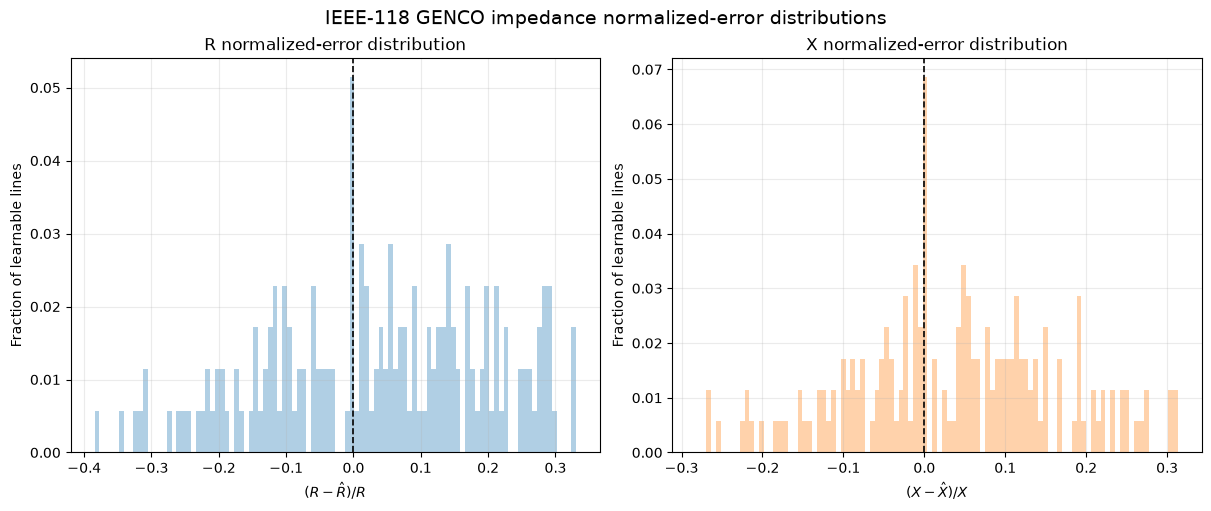

In [20]:
# Plot the normalized-error distributions for the GENCO impedance estimates.
impedance_error_components = (
    ("resistance", "R", "tab:blue"),
    ("reactance", "X", "tab:orange"),
)
fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)

for ax, (component, symbol, color) in zip(axes, impedance_error_components):
    aged = impedance_result[f"actual_aged_{component}_pu"][plot_mask].numpy()
    estimated = impedance_result[f"estimated_{component}_pu"][plot_mask].numpy()
    valid = (
        np.isfinite(aged)
        & np.isfinite(estimated)
        & (np.abs(aged) > IMPEDANCE_DENOMINATOR_EPS)
    )
    if not valid.any():
        raise ValueError(f"No valid nonzero {symbol} values are available")

    relative_residual = (aged[valid] - estimated[valid]) / aged[valid]
    bins = histogram_bins({component: relative_residual})
    fractions = histogram_fractions(relative_residual, bins)
    ax.stairs(
        fractions,
        bins,
        color=color,
        linewidth=1.5,
        fill=True,
        alpha=0.35,
    )
    ax.axvline(0.0, color="black", linestyle="--", linewidth=1.2)
    ax.set_xlabel(rf"$({symbol} - \hat{{{symbol}}}) / {symbol}$")
    ax.set_ylabel("Fraction of learnable lines")
    ax.grid(alpha=0.25)

error_distribution_path = OUTPUT_DIR / "impedance_relative_error_distributions.pdf"
fig.savefig(error_distribution_path, dpi=300, bbox_inches="tight")
print(f"Saved error-distribution plot to {error_distribution_path}")
plt.show()

aged_comparison_true PF:   0%|          | 0/63 [00:00<?, ?it/s]

Saved 118,000 rows to results/local_predictions/aged_comparison_true_pf_ground_truth_predictions.parquet


aged_comparison_original PF:   0%|          | 0/63 [00:00<?, ?it/s]

Saved 118,000 rows to results/local_predictions/aged_comparison_original_pf_ground_truth_predictions.parquet


aged_comparison_estimated PF:   0%|          | 0/63 [00:00<?, ?it/s]

Saved 118,000 rows to results/local_predictions/aged_comparison_estimated_pf_ground_truth_predictions.parquet
Saved histogram to results/local_predictions/estimated_impedance_pf_error_histograms.png


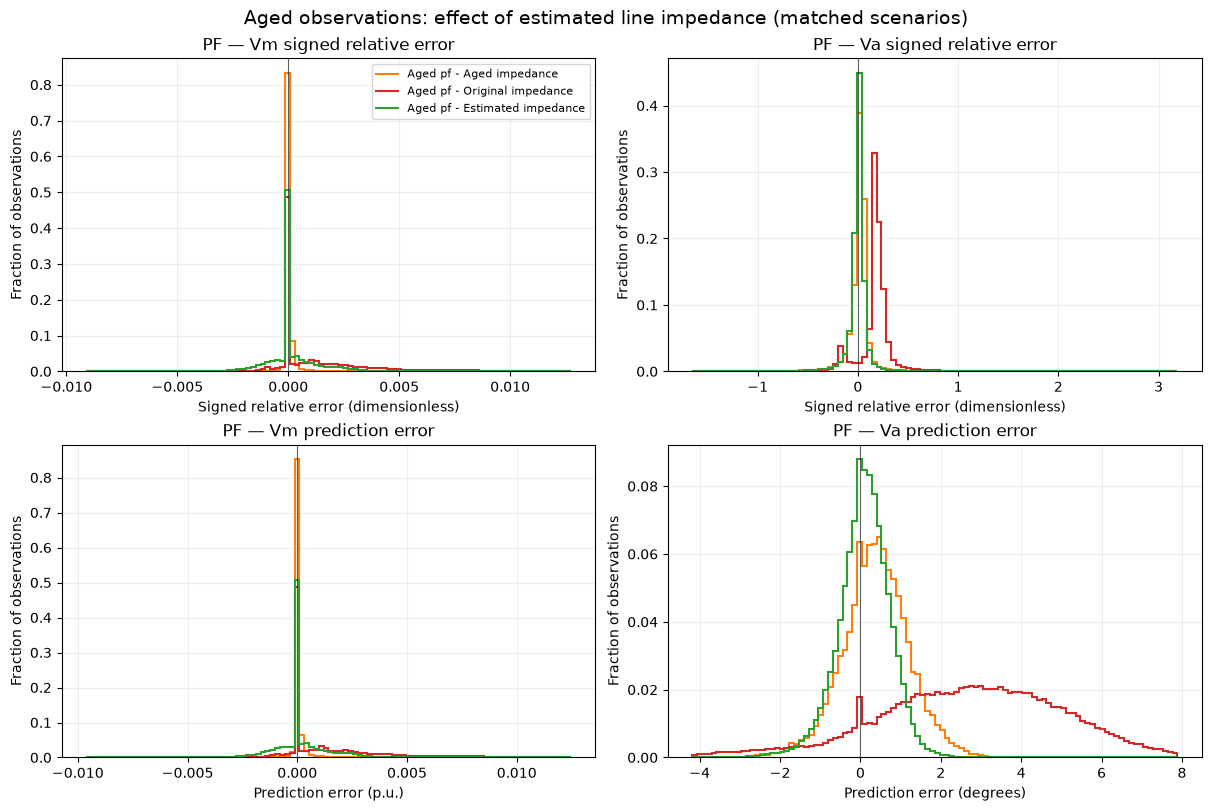

Positive RMSE reduction means improvement over original impedance.
Scenarios used to estimate impedance are not a held-out evaluation.


,input,variable,scope,unit,count,MAE,RMSE,RMSE reduction vs original (%)
0,Aged pf - Aged impedance,Vm,all,p.u.,118000,0.000262,0.002105,38.914014
1,Aged pf - Aged impedance,Vm,masked,p.u.,65000,0.000477,0.002836,38.914014
2,Aged pf - Original impedance,Vm,all,p.u.,118000,0.001655,0.003446,0.000000
3,Aged pf - Original impedance,Vm,masked,p.u.,65000,0.003004,0.004643,0.000000
4,Aged pf - Estimated impedance,Vm,all,p.u.,118000,0.000735,0.002056,40.334380
5,Aged pf - Estimated impedance,Vm,masked,p.u.,65000,0.001335,0.002770,40.334380
6,Aged pf - Aged impedance,Va,all,degrees,118000,0.720932,0.918021,74.222397
7,Aged pf - Aged impedance,Va,masked,degrees,117000,0.727094,0.921936,74.222397
8,Aged pf - Original impedance,Va,all,degrees,118000,3.035221,3.561313,0.000000
9,Aged pf - Original impedance,Va,masked,degrees,117000,3.061163,3.576500,0.000000


In [ ]:
# Same 2x2 layout as In [13]: Vm/Va relative errors and prediction errors.
# Compare GENCO errors using aged observations and three impedance inputs.
# Load the saved estimate: rerunning optimization is unnecessary.
estimated_pf_result = torch.load(
    OUTPUT_DIR / "denoised_admittance.pt", map_location="cpu", weights_only=True
)
estimated_pf_y = estimated_pf_result["estimated_admittance_normalized"]
estimated_pf_edges = estimated_pf_result["edge_index"]
estimated_pf_mask = estimated_pf_result["learnable_line_mask"].bool()
estimated_pf_directed_mask = torch.cat([estimated_pf_mask, estimated_pf_mask])
if estimated_pf_y.shape != (estimated_pf_edges.size(1), 4):
    raise ValueError("Saved admittance shape does not match saved edges")
if estimated_pf_directed_mask.numel() != estimated_pf_edges.size(1):
    raise ValueError("Saved learnability mask does not match saved edges")
if not torch.isfinite(estimated_pf_y).all():
    raise ValueError("Saved estimated admittance contains non-finite values")


def prepare_estimated_pf_graph(dataset, index):
    graph = dataset[index].clone()
    if not torch.equal(graph[edge_type].edge_index.cpu(), estimated_pf_edges):
        raise ValueError(f"Saved estimate edge ordering differs for scenario {index}")
    # Use exactly the substitution used during estimation; fixed branches
    # and all aged observations, targets, and PF masks retain their values.
    edge_attr = graph[edge_type].edge_attr.clone()
    current_y = edge_attr[:, admittance_columns].clone()
    current_y[estimated_pf_directed_mask] = estimated_pf_y.to(current_y)[
        estimated_pf_directed_mask
    ]
    edge_attr[:, admittance_columns] = current_y
    graph[edge_type].edge_attr = edge_attr
    return pf_transform(graph)


# Evaluate identical matched scenarios for every curve. Recompute predictions
# so an older cached run cannot hide changes to the data or saved estimate.
estimated_pf_indices = sorted(hidden_aging_indices)
if not estimated_pf_indices:
    raise ValueError("No matched scenarios are available for comparison")
estimated_pf_runs = {
    "Aged pf - Aged impedance": ("aged_comparison_true", prepare_graph),
    "Aged pf - Original impedance": (
        "aged_comparison_original",
        prepare_hidden_aging_graph,
    ),
    "Aged pf - Estimated impedance": (
        "aged_comparison_estimated",
        prepare_estimated_pf_graph,
    ),
}
estimated_pf_tables = {}
model.eval()
for label, (run_name, graph_preparer) in estimated_pf_runs.items():
    path = predict_all(
        run_name,
        aged_dataset,
        indices=estimated_pf_indices,
        graph_preparer=graph_preparer,
    )
    estimated_pf_tables[label] = (
        pd.read_parquet(path).sort_values(key_columns).reset_index(drop=True)
    )

estimated_pf_reference = estimated_pf_tables["Aged pf - Aged impedance"]
for label, table in estimated_pf_tables.items():
    if table.duplicated(key_columns).any():
        raise ValueError(f"Duplicate prediction row keys for {label}")
    if not table[key_columns].equals(estimated_pf_reference[key_columns]):
        raise ValueError(f"Comparison row keys differ for {label}")
    for variable, (gt_column, _, _) in error_specs.items():
        if not np.allclose(table[gt_column], estimated_pf_reference[gt_column]):
            raise ValueError(f"Ground truths differ for {label}: {variable}")
        mask_column = {"Vm": "vm_masked", "Va": "va_masked"}[variable]
        if not table[mask_column].equals(estimated_pf_reference[mask_column]):
            raise ValueError(f"PF masks differ for {label}: {variable}")

estimated_pf_colors = {
    "Aged pf - Aged impedance": "tab:orange",
    "Aged pf - Original impedance": "tab:red",
    "Aged pf - Estimated impedance": "tab:green",
}
fig, axes = plt.subplots(2, 2, figsize=(12, 8), constrained_layout=True)
estimated_pf_metrics = []
for col, (variable, (gt_column, pred_column, unit)) in enumerate(error_specs.items()):
    for row, (kind, error_label) in enumerate(plot_rows):
        error_function = relative_error if kind == "relative" else prediction_error
        errors = {}
        for label, table in estimated_pf_tables.items():
            values = error_function(table[gt_column], table[pred_column])
            errors[label] = values[np.isfinite(values)]
        bins = histogram_bins(errors)
        ax = axes[row, col]
        for label, values in errors.items():
            ax.stairs(
                histogram_fractions(values, bins),
                bins,
                label=label,
                color=estimated_pf_colors[label],
                linewidth=1.5,
            )
        ax.axvline(0, color="black", linewidth=0.8, alpha=0.6)
        x_unit = "dimensionless" if kind == "relative" else unit
        ax.set_xlabel(f"{error_label} ({x_unit})")
        ax.set_ylabel("Fraction of observations")
        ax.grid(alpha=0.2)
        if row == 0 and col == 0:
            ax.legend(fontsize=8)

    # Metrics use all finite errors, including histogram tails. Report both
    # all buses (as in In [13]) and only quantities hidden by the PF task.
    for label, table in estimated_pf_tables.items():
        values = prediction_error(table[gt_column], table[pred_column])
        masked = table[{"Vm": "vm_masked", "Va": "va_masked"}[variable]].to_numpy(bool)
        for scope, selection in (
            ("all", np.ones(len(values), dtype=bool)),
            ("masked", masked),
        ):
            selected = values[selection & np.isfinite(values)]
            estimated_pf_metrics.append(
                {
                    "input": label,
                    "variable": variable,
                    "scope": scope,
                    "unit": unit,
                    "count": selected.size,
                    "MAE": np.abs(selected).mean() if selected.size else np.nan,
                    "RMSE": np.sqrt(np.mean(selected**2)) if selected.size else np.nan,
                }
            )

estimated_pf_histogram_path = OUTPUT_DIR / "estimated_impedance_pf_error_histograms.pdf"
fig.savefig(estimated_pf_histogram_path, dpi=300, bbox_inches="tight")
print(f"Saved histogram to {estimated_pf_histogram_path}")
plt.show()

### PF error distributions at each branch endpoint

Each curve below represents one physical branch over the available aged scenarios, using estimated impedance as GENCO input. Vm and Va belong to buses, so the rows show the from-bus and to-bus errors separately. Branches sharing an endpoint share that endpoint's error distribution. All branches and all PF predictions are included, including known voltage quantities. These are empirical histograms; no normal distribution is assumed. Shared bins span the combined per-branch 0.5th–99.5th percentile ranges, as in the previous plots.


Saved branch endpoint histograms to results/local_predictions/estimated_impedance_pf_error_by_branch.png
Black curve: branch 1. Shared buses produce overlapping curves.


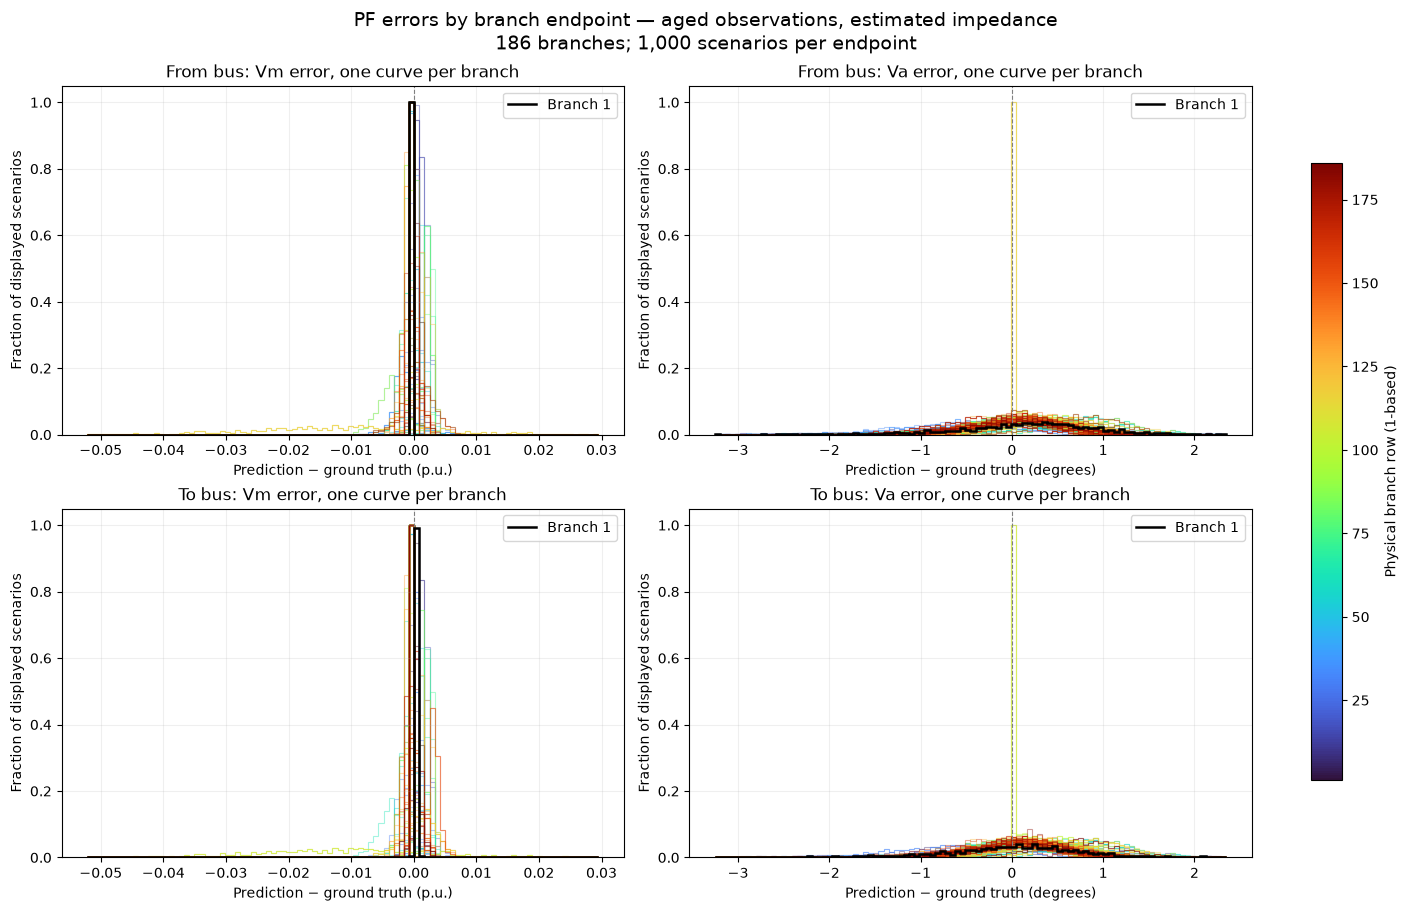

In [ ]:
# One error histogram per physical branch, with 1,000 scenarios in this dataset.
branch_pf_predictions = pd.read_parquet(
    OUTPUT_DIR / "aged_comparison_estimated_pf_ground_truth_predictions.parquet"
)
branch_pf_result = torch.load(
    OUTPUT_DIR / "denoised_admittance.pt", map_location="cpu", weights_only=True
)
branch_pf_edges = branch_pf_result["edge_index"].numpy()
branch_pf_count = branch_pf_edges.shape[1] // 2
if not np.array_equal(
    branch_pf_edges[:, :branch_pf_count], branch_pf_edges[::-1, branch_pf_count:]
):
    raise ValueError("Saved branch directions are not aligned")
if branch_pf_predictions.duplicated(
    ["dataset_index", "scenario_id", "bus_index"]
).any():
    raise ValueError("Duplicate scenario/bus prediction rows")
branch_pf_sample_count = branch_pf_predictions["dataset_index"].nunique()
branch_pf_groups = dict(tuple(branch_pf_predictions.groupby("bus_index")))
branch_pf_scenarios = set(branch_pf_predictions["dataset_index"])
for bus_index in np.unique(branch_pf_edges):
    if (
        bus_index not in branch_pf_groups
        or set(branch_pf_groups[bus_index]["dataset_index"]) != branch_pf_scenarios
    ):
        raise ValueError(f"Incomplete scenario coverage at bus index {bus_index}")

branch_pf_cmap = plt.get_cmap("turbo")
branch_pf_norm = plt.Normalize(1, max(branch_pf_count, 2))
fig, axes = plt.subplots(2, 2, figsize=(14, 9), constrained_layout=True)
branch_pf_summary = []
for col, (variable, (gt_column, pred_column, unit)) in enumerate(error_specs.items()):
    # Use identical bins for the from/to panels of each voltage quantity.
    endpoint_errors = {}
    for endpoint, endpoint_name in enumerate(("From bus", "To bus")):
        for branch in range(branch_pf_count):
            bus_index = int(branch_pf_edges[endpoint, branch])
            table = branch_pf_groups[bus_index]
            errors = prediction_error(table[gt_column], table[pred_column])
            errors = errors[np.isfinite(errors)]
            endpoint_errors[(endpoint, branch)] = errors
            branch_pf_summary.append(
                {
                    "branch_row": branch + 1,
                    "endpoint": endpoint_name,
                    "bus_index": bus_index,
                    "variable": variable,
                    "unit": unit,
                    "count": errors.size,
                    "mean_error": errors.mean() if errors.size else np.nan,
                    "std_error": errors.std() if errors.size else np.nan,
                    "RMSE": np.sqrt(np.mean(errors**2)) if errors.size else np.nan,
                }
            )
    bins = histogram_bins(endpoint_errors)
    for endpoint, endpoint_name in enumerate(("From bus", "To bus")):
        ax = axes[endpoint, col]
        for branch in range(branch_pf_count):
            fractions = histogram_fractions(endpoint_errors[(endpoint, branch)], bins)
            ax.stairs(
                fractions,
                bins,
                color=branch_pf_cmap(branch_pf_norm(branch + 1)),
                alpha=0.4,
                linewidth=0.8,
            )
        # Highlight the user's example without a 186-entry legend.
        ax.stairs(
            histogram_fractions(endpoint_errors[(endpoint, 0)], bins),
            bins,
            color="black",
            linewidth=1.8,
            label="Branch 1",
            zorder=5,
        )
        ax.axvline(0, color="grey", linestyle="--", linewidth=0.8)
        ax.set_xlabel(f"Prediction − ground truth ({unit})")
        ax.set_ylabel("Fraction of displayed scenarios")
        ax.grid(alpha=0.2)
        ax.legend()
fig.colorbar(
    plt.cm.ScalarMappable(norm=branch_pf_norm, cmap=branch_pf_cmap),
    ax=axes,
    label="Physical branch row (1-based)",
    shrink=0.8,
)
branch_pf_path = OUTPUT_DIR / "estimated_impedance_pf_error_by_branch.pdf"
fig.savefig(branch_pf_path, dpi=300, bbox_inches="tight")
pd.DataFrame(branch_pf_summary).to_csv(
    OUTPUT_DIR / "estimated_impedance_pf_error_by_branch_summary.csv", index=False
)
print(f"Saved branch endpoint histograms to {branch_pf_path}")
print("Black curve: branch 1. Shared buses produce overlapping curves.")
plt.show()

## 8. Penalised negative direction for R and X

In Section 7, we accept a specific kind of gradient and reject the other kind. To be specific, only gradients that push R and X to higher values are accepted. In that implementation, we have to reduce the learning rate so that the steps we take towards increasing R/X are not so big that they exceed their actual values, which leads to a slow learning process.

I want another implementation that lets R/X update in both directions. In this way, I can increase the learning rate and speed up the training process. To prevent the model from pushing the R/X to negative values, I want to penalise the gradients that are in the wrong direction. I want a higher-order optimiser to do so.
Implement a R/X estimation procedure and plot the same results as previous section.


In [ ]:
from scipy.optimize import minimize

# L-BFGS-B is a limited-memory quasi-Newton method: it uses gradient
# differences to approximate inverse-Hessian curvature and selects its step
# length with a line search. Unlike Section 7, multipliers may move below or
# above 1. A one-sided quadratic penalty supplies a corrective gradient near
# zero, and a tiny hard lower bound is retained as a numerical safeguard.
PENALIZED_MAX_ITER = 30
PENALIZED_MAX_FUN = 150
PENALIZED_MAX_LINE_SEARCH_STEPS = 20
PENALIZED_HISTORY_SIZE = 20
PENALIZED_FTOL = 1e-10
PENALIZED_GTOL = 1e-6
PENALTY_WEIGHT = 10.0
PENALTY_START_MULTIPLIER = 0.05
PENALIZED_MULTIPLIER_FLOOR = 1e-6
PENALIZED_Y_PATH = OUTPUT_DIR / "denoised_admittance_penalized_lbfgsb.pt"
PENALIZED_TB_RUN_NAME = datetime.now().strftime("penalized-lbfgsb-rx-%Y%m%d-%H%M%S")
PENALIZED_TB_DIR = PROJECT_DIR / "tb" / PENALIZED_TB_RUN_NAME

penalized_line_indices = learnable_line_mask.nonzero(as_tuple=False).flatten()
n_penalized_lines = int(penalized_line_indices.numel())
if n_penalized_lines == 0:
    raise RuntimeError("No lines are available for penalized R/X optimization")
if (initial_resistance[learnable_line_mask] <= 0).any():
    raise ValueError("Learnable-line resistance must be positive")
if (initial_reactance[learnable_line_mask] <= 0).any():
    raise ValueError("Learnable-line reactance must be positive")

penalized_resistance_multiplier = torch.nn.Parameter(
    torch.ones(n_penalized_lines, dtype=initial_resistance.dtype)
)
penalized_reactance_multiplier = torch.nn.Parameter(
    torch.ones(n_penalized_lines, dtype=initial_reactance.dtype)
)
penalized_parameters = [
    penalized_resistance_multiplier,
    penalized_reactance_multiplier,
]


def penalized_estimated_impedance_components():
    """Return full R/X vectors from independently optimized multipliers."""
    resistance = initial_resistance.clone()
    reactance = initial_reactance.clone()
    resistance[penalized_line_indices] = (
        initial_resistance[penalized_line_indices] * penalized_resistance_multiplier
    )
    reactance[penalized_line_indices] = (
        initial_reactance[penalized_line_indices] * penalized_reactance_multiplier
    )
    return resistance, reactance


def penalized_admittance_from_impedance():
    """Differentiably convert the penalized R/X estimate to normalized Y."""
    resistance, reactance = penalized_estimated_impedance_components()
    impedance = torch.complex(resistance, reactance)
    series_y = admittance_scale / impedance
    estimated = initial_admittance.clone()

    forward_values = torch.stack(
        [
            (series_y + forward_shunt).real,
            (series_y + forward_shunt).imag,
            -series_y.real,
            -series_y.imag,
        ],
        dim=1,
    )
    reverse_values = torch.stack(
        [
            (series_y + reverse_shunt).real,
            (series_y + reverse_shunt).imag,
            -series_y.real,
            -series_y.imag,
        ],
        dim=1,
    )
    estimated[penalized_line_indices] = forward_values[penalized_line_indices]
    estimated[n_lines + penalized_line_indices] = reverse_values[penalized_line_indices]
    return estimated


def positivity_penalty():
    """One-sided penalty whose gradient pushes near-zero multipliers up."""
    resistance_violation = torch.relu(
        PENALTY_START_MULTIPLIER - penalized_resistance_multiplier
    )
    reactance_violation = torch.relu(
        PENALTY_START_MULTIPLIER - penalized_reactance_multiplier
    )
    return (
        0.5
        * PENALTY_WEIGHT
        * (resistance_violation.square().mean() + reactance_violation.square().mean())
    )


def set_penalized_parameters(values):
    """Copy one packed SciPy vector into the R and X multipliers."""
    values = np.asarray(values, dtype=np.float64)
    expected_shape = (2 * n_penalized_lines,)
    if values.shape != expected_shape:
        raise ValueError(f"Expected {expected_shape}, got {values.shape}")
    with torch.no_grad():
        penalized_resistance_multiplier.copy_(
            torch.as_tensor(
                values[:n_penalized_lines],
                dtype=penalized_resistance_multiplier.dtype,
            )
        )
        penalized_reactance_multiplier.copy_(
            torch.as_tensor(
                values[n_penalized_lines:],
                dtype=penalized_reactance_multiplier.dtype,
            )
        )


def penalized_impedance_metrics():
    """Diagnostic impedance errors; aged R/X never enter the objective."""
    resistance, reactance = penalized_estimated_impedance_components()
    resistance_mismatch = (actual_aged_resistance - resistance.detach())[
        learnable_line_mask
    ]
    reactance_mismatch = (actual_aged_reactance - reactance.detach())[
        learnable_line_mask
    ]
    combined = torch.cat([resistance_mismatch, reactance_mismatch])
    return resistance_mismatch, reactance_mismatch, combined


penalized_evaluations = 0
penalized_last_evaluation = {}
penalized_history = []


def penalized_lbfgsb_objective(values):
    """Return full-dataset model loss + positivity penalty and gradient."""
    global penalized_evaluations, penalized_last_evaluation
    set_penalized_parameters(values)
    for parameter in penalized_parameters:
        parameter.grad = None

    model_loss_sum = 0.0
    target_count = 0
    for start in range(0, len(training_indices), BATCH_SIZE):
        batch_indices = training_indices[start : start + BATCH_SIZE]
        current_admittance = penalized_admittance_from_impedance()
        graphs = [
            prepare_denoising_graph(index, current_admittance)
            for index in batch_indices
        ]
        batch = Batch.from_data_list(graphs).to(DEVICE)
        model_loss, batch_target_count = masked_pf_model_loss(batch, model(batch))
        (model_loss * batch_target_count).backward()
        model_loss_sum += model_loss.detach().item() * batch_target_count
        target_count += batch_target_count

    if target_count == 0:
        raise RuntimeError("Penalized objective has no supervised PF targets")

    model_gradients = []
    for parameter in penalized_parameters:
        if parameter.grad is None:
            raise RuntimeError("GENCO did not propagate gradients to R/X")
        model_gradients.append(parameter.grad.detach().clone() / target_count)

    penalty = positivity_penalty()
    penalty_gradients = torch.autograd.grad(penalty, penalized_parameters)
    total_gradients = [
        model_gradient + penalty_gradient
        for model_gradient, penalty_gradient in zip(model_gradients, penalty_gradients)
    ]
    gradient = torch.cat(total_gradients).detach().cpu().double().numpy().copy()
    model_mse = model_loss_sum / target_count
    penalty_value = penalty.detach().item()
    objective = model_mse + penalty_value
    if not np.isfinite(objective) or not np.isfinite(gradient).all():
        raise RuntimeError("Non-finite penalized objective or gradient")

    penalized_evaluations += 1
    penalized_last_evaluation = {
        "x": np.asarray(values, dtype=np.float64).copy(),
        "objective": float(objective),
        "model_mse": float(model_mse),
        "positivity_penalty": float(penalty_value),
        "gradient_norm": float(np.linalg.norm(gradient)),
    }
    if penalized_evaluations == 1:
        resistance_mismatch, reactance_mismatch, combined = (
            penalized_impedance_metrics()
        )
        initial_metrics = {
            **penalized_last_evaluation,
            "function_evaluations": penalized_evaluations,
            "impedance_mismatch_mae": combined.abs().mean().item(),
            "impedance_mismatch_rmse": (combined.square().mean().sqrt().item()),
            "resistance_mismatch_rmse": (
                resistance_mismatch.square().mean().sqrt().item()
            ),
            "reactance_mismatch_rmse": (
                reactance_mismatch.square().mean().sqrt().item()
            ),
        }
        log_penalized_tensorboard(
            penalized_writer,
            0,
            initial_metrics,
            resistance_mismatch,
            reactance_mismatch,
        )
    return float(objective), gradient


def log_penalized_tensorboard(
    writer, step, metrics, resistance_mismatch, reactance_mismatch
):
    """Log accepted L-BFGS-B iterates without multiplier-specific tags."""
    writer.add_scalar("iteration/objective", metrics["objective"], step)
    writer.add_scalar("iteration/model_rmse", metrics["model_mse"] ** 0.5, step)
    writer.add_scalar(
        "iteration/positivity_penalty",
        metrics["positivity_penalty"],
        step,
    )
    writer.add_scalar("iteration/gradient_norm", metrics["gradient_norm"], step)
    writer.add_scalar(
        "iteration/function_evaluations",
        metrics["function_evaluations"],
        step,
    )
    writer.add_scalar(
        "iteration/impedance_mismatch_mae",
        metrics["impedance_mismatch_mae"],
        step,
    )
    writer.add_scalar(
        "iteration/impedance_mismatch_rmse",
        metrics["impedance_mismatch_rmse"],
        step,
    )
    writer.add_scalar(
        "iteration/resistance_mismatch_rmse",
        metrics["resistance_mismatch_rmse"],
        step,
    )
    writer.add_scalar(
        "iteration/reactance_mismatch_rmse",
        metrics["reactance_mismatch_rmse"],
        step,
    )
    writer.add_histogram("iteration/resistance_mismatch", resistance_mismatch, step)
    writer.add_histogram("iteration/reactance_mismatch", reactance_mismatch, step)
    writer.flush()


def record_penalized_iteration(values):
    """Record and print one accepted quasi-Newton iterate."""
    set_penalized_parameters(values)
    resistance_mismatch, reactance_mismatch, combined = penalized_impedance_metrics()
    cached_values = penalized_last_evaluation.get("x")
    cache_matches = cached_values is not None and np.allclose(
        values, cached_values, rtol=0.0, atol=1e-12
    )
    if not cache_matches:
        penalized_lbfgsb_objective(values)
        set_penalized_parameters(values)
        cache_matches = True
    penalized_history.append(
        {
            "iteration": len(penalized_history) + 1,
            "function_evaluations": penalized_evaluations,
            "objective": (
                penalized_last_evaluation["objective"]
                if cache_matches
                else float("nan")
            ),
            "model_mse": (
                penalized_last_evaluation["model_mse"]
                if cache_matches
                else float("nan")
            ),
            "positivity_penalty": (
                penalized_last_evaluation["positivity_penalty"]
                if cache_matches
                else float("nan")
            ),
            "gradient_norm": (
                penalized_last_evaluation["gradient_norm"]
                if cache_matches
                else float("nan")
            ),
            "impedance_mismatch_mae": combined.abs().mean().item(),
            "impedance_mismatch_rmse": (combined.square().mean().sqrt().item()),
            "resistance_mismatch_rmse": (
                resistance_mismatch.square().mean().sqrt().item()
            ),
            "reactance_mismatch_rmse": (
                reactance_mismatch.square().mean().sqrt().item()
            ),
            "minimum_resistance_multiplier": (
                penalized_resistance_multiplier.detach().min().item()
            ),
            "minimum_reactance_multiplier": (
                penalized_reactance_multiplier.detach().min().item()
            ),
        }
    )
    current = penalized_history[-1]
    log_penalized_tensorboard(
        penalized_writer,
        current["iteration"],
        current,
        resistance_mismatch,
        reactance_mismatch,
    )
    print(
        f"Accepted iteration {current['iteration']:02d}: "
        f"model RMSE={current['model_mse'] ** 0.5:.6e}, "
        f"penalty={current['positivity_penalty']:.3e}, "
        f"R/X mismatch RMSE={current['impedance_mismatch_rmse']:.6e}"
    )


# Start from the original network. Both multiplier blocks have lower bounds
# near zero and no upper bounds, so each R/X estimate can decrease or increase.
penalized_initial_values = np.ones(2 * n_penalized_lines, dtype=np.float64)
penalized_bounds = [(PENALIZED_MULTIPLIER_FLOOR, None)] * penalized_initial_values.size
penalized_writer = SummaryWriter(log_dir=str(PENALIZED_TB_DIR))
try:
    penalized_lbfgsb_result = minimize(
        penalized_lbfgsb_objective,
        penalized_initial_values,
        method="L-BFGS-B",
        jac=True,
        bounds=penalized_bounds,
        callback=record_penalized_iteration,
        options={
            "maxiter": PENALIZED_MAX_ITER,
            "maxfun": PENALIZED_MAX_FUN,
            "maxls": PENALIZED_MAX_LINE_SEARCH_STEPS,
            "maxcor": PENALIZED_HISTORY_SIZE,
            "ftol": PENALIZED_FTOL,
            "gtol": PENALIZED_GTOL,
        },
    )
finally:
    penalized_writer.close()
set_penalized_parameters(penalized_lbfgsb_result.x)

cached_values = penalized_last_evaluation.get("x")
if cached_values is None or not np.allclose(
    penalized_lbfgsb_result.x, cached_values, rtol=0.0, atol=1e-12
):
    penalized_lbfgsb_objective(penalized_lbfgsb_result.x)
    set_penalized_parameters(penalized_lbfgsb_result.x)

penalized_estimated_resistance, penalized_estimated_reactance = (
    penalized_estimated_impedance_components()
)
penalized_final_admittance = penalized_admittance_from_impedance().detach().cpu()
penalized_resistance_mismatch, penalized_reactance_mismatch, penalized_combined = (
    penalized_impedance_metrics()
)
if (penalized_resistance_multiplier <= 0).any():
    raise RuntimeError("The final resistance estimate is not positive")
if (penalized_reactance_multiplier <= 0).any():
    raise RuntimeError("The final reactance estimate is not positive")

torch.save(
    {
        "edge_index": reference_edge_index,
        "learnable_line_mask": learnable_line_mask,
        "estimated_resistance_pu": (penalized_estimated_resistance.detach().cpu()),
        "estimated_reactance_pu": (penalized_estimated_reactance.detach().cpu()),
        "estimated_resistance_multiplier": (
            penalized_resistance_multiplier.detach().cpu()
        ),
        "estimated_reactance_multiplier": (
            penalized_reactance_multiplier.detach().cpu()
        ),
        "initial_resistance_pu": initial_resistance,
        "initial_reactance_pu": initial_reactance,
        "actual_aged_resistance_pu": actual_aged_resistance,
        "actual_aged_reactance_pu": actual_aged_reactance,
        "estimated_admittance_normalized": penalized_final_admittance,
        "initial_admittance_normalized": initial_admittance,
        "actual_aged_admittance_normalized": actual_aged_admittance,
        "original_scenario_std": original_admittance_std,
        "aged_scenario_std": aged_admittance_std,
        "training_indices": torch.as_tensor(training_indices),
        "optimizer": "penalized L-BFGS-B",
        "optimizer_success": bool(penalized_lbfgsb_result.success),
        "optimizer_status": int(penalized_lbfgsb_result.status),
        "optimizer_message": str(penalized_lbfgsb_result.message),
        "iterations": int(penalized_lbfgsb_result.nit),
        "function_evaluations": int(penalized_evaluations),
        "final_objective": penalized_last_evaluation["objective"],
        "final_model_mse": penalized_last_evaluation["model_mse"],
        "final_positivity_penalty": (penalized_last_evaluation["positivity_penalty"]),
        "final_gradient_norm": (penalized_last_evaluation["gradient_norm"]),
        "impedance_mismatch_mae": penalized_combined.abs().mean().item(),
        "impedance_mismatch_rmse": (penalized_combined.square().mean().sqrt().item()),
        "history": penalized_history,
        "penalty_weight": PENALTY_WEIGHT,
        "penalty_start_multiplier": PENALTY_START_MULTIPLIER,
        "multiplier_lower_bound": PENALIZED_MULTIPLIER_FLOOR,
        "penalty_formula": (
            "0.5 * lambda * (mean(relu(tau - m_R)^2) + " "mean(relu(tau - m_X)^2))"
        ),
        "constraint": (
            "R/X multipliers may move in both directions and remain positive"
        ),
    },
    PENALIZED_Y_PATH,
)

print(penalized_lbfgsb_result.message)
print(
    f"Penalized L-BFGS-B finished after {penalized_lbfgsb_result.nit} "
    f"iterations and {penalized_evaluations} full-dataset evaluations"
)
print(f"Final model RMSE: " f"{penalized_last_evaluation['model_mse'] ** 0.5:.6e}")
print(
    f"Final positivity penalty: "
    f"{penalized_last_evaluation['positivity_penalty']:.6e}"
)
print(
    "Final R/X mismatch RMSE: "
    f"{penalized_combined.square().mean().sqrt().item():.6e}"
)
print(f"Saved penalized L-BFGS-B result to {PENALIZED_Y_PATH}")
print(f"TensorBoard logs: {PENALIZED_TB_DIR}")
print(f"Launch with: tensorboard --logdir {PENALIZED_TB_DIR}")

In [ ]:
# Compare original, aged, and penalized L-BFGS-B impedance values.
penalized_impedance_result = torch.load(
    PENALIZED_Y_PATH,
    map_location="cpu",
    weights_only=True,
)
penalized_plot_mask = penalized_impedance_result["learnable_line_mask"].bool()
penalized_branch_rows = torch.arange(1, penalized_plot_mask.numel() + 1)[
    penalized_plot_mask
].numpy()


def plot_penalized_impedance_component(component, ylabel, output_name):
    original = penalized_impedance_result[f"initial_{component}_pu"][
        penalized_plot_mask
    ].numpy()
    aged = penalized_impedance_result[f"actual_aged_{component}_pu"][
        penalized_plot_mask
    ].numpy()
    estimated = penalized_impedance_result[f"estimated_{component}_pu"][
        penalized_plot_mask
    ].numpy()

    fig, ax = plt.subplots(figsize=(16, 5), constrained_layout=True)
    ax.plot(
        penalized_branch_rows,
        original,
        label="Original",
        color="tab:blue",
        linewidth=1.5,
    )
    ax.plot(
        penalized_branch_rows,
        aged,
        label="Aged (ground truth)",
        color="tab:orange",
        linewidth=1.5,
    )
    ax.plot(
        penalized_branch_rows,
        estimated,
        label="Estimated (penalized L-BFGS-B)",
        color="tab:purple",
        linewidth=1.5,
        linestyle="--",
    )
    ax.set_xlabel("MATPOWER branch row")
    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.25)
    ax.legend()

    output_path = OUTPUT_DIR / output_name
    fig.savefig(output_path, dpi=300, bbox_inches="tight")
    print(f"Saved plot to {output_path}")
    plt.show()


plot_penalized_impedance_component(
    "resistance",
    "Resistance R (p.u.)",
    "resistance_comparison_penalized_lbfgsb.pdf",
)
plot_penalized_impedance_component(
    "reactance",
    "Reactance X (p.u.)",
    "reactance_comparison_penalized_lbfgsb.pdf",
)

In [ ]:
# Parity plots for the penalized L-BFGS-B estimates.
def plot_penalized_impedance_parity(component, symbol, output_name):
    aged = penalized_impedance_result[f"actual_aged_{component}_pu"][
        penalized_plot_mask
    ].numpy()
    estimated = penalized_impedance_result[f"estimated_{component}_pu"][
        penalized_plot_mask
    ].numpy()
    valid = np.isfinite(aged) & np.isfinite(estimated)
    if not valid.any():
        raise ValueError(f"No valid {symbol} values are available to plot")

    aged = aged[valid]
    estimated = estimated[valid]
    lower = min(aged.min(), estimated.min())
    upper = max(aged.max(), estimated.max())
    if lower == upper:
        padding = max(abs(lower) * 0.05, 1e-12)
        lower -= padding
        upper += padding

    fig, ax = plt.subplots(figsize=(7, 7), constrained_layout=True)
    ax.scatter(
        estimated,
        aged,
        s=22,
        color="tab:purple",
        alpha=0.8,
        label="Learnable lines",
    )
    ax.plot(
        [lower, upper],
        [lower, upper],
        color="black",
        linestyle="--",
        linewidth=1.2,
        label="Perfect estimate (y = x)",
    )
    ax.set_xlim(lower, upper)
    ax.set_ylim(lower, upper)
    ax.set_aspect("equal", adjustable="box")
    ax.set_xlabel(f"Estimated {symbol} (p.u.)")
    ax.set_ylabel(f"Aged ground-truth {symbol} (p.u.)")
    ax.grid(alpha=0.25)
    ax.legend()

    output_path = OUTPUT_DIR / output_name
    fig.savefig(output_path, dpi=300, bbox_inches="tight")
    print(f"Saved parity plot to {output_path}")
    plt.show()


plot_penalized_impedance_parity(
    "resistance",
    "R",
    "resistance_estimated_vs_aged_penalized_lbfgsb.pdf",
)
plot_penalized_impedance_parity(
    "reactance",
    "X",
    "reactance_estimated_vs_aged_penalized_lbfgsb.pdf",
)

In [ ]:
# Normalized-residual plots for the penalized L-BFGS-B estimates.
def plot_penalized_relative_residual(component, symbol, output_name):
    aged = penalized_impedance_result[f"actual_aged_{component}_pu"][
        penalized_plot_mask
    ].numpy()
    estimated = penalized_impedance_result[f"estimated_{component}_pu"][
        penalized_plot_mask
    ].numpy()
    valid = (
        np.isfinite(aged)
        & np.isfinite(estimated)
        & (np.abs(aged) > IMPEDANCE_DENOMINATOR_EPS)
    )
    if not valid.any():
        raise ValueError(f"No valid nonzero {symbol} values are available")

    aged = aged[valid]
    estimated = estimated[valid]
    relative_residual = (aged - estimated) / aged

    fig, ax = plt.subplots(figsize=(8, 6), constrained_layout=True)
    ax.scatter(
        aged,
        relative_residual,
        s=22,
        color="tab:purple",
        alpha=0.8,
        label="Learnable lines",
    )
    ax.axhline(
        0.0,
        color="black",
        linestyle="--",
        linewidth=1.2,
        label="Perfect estimate (relative residual = 0)",
    )
    ax.set_xlabel(f"Aged ground-truth {symbol} (p.u.)")
    ax.set_ylabel(rf"$({symbol} - \hat{{{symbol}}}) / {symbol}$")
    ax.grid(alpha=0.25)
    ax.legend()

    output_path = OUTPUT_DIR / output_name
    fig.savefig(output_path, dpi=300, bbox_inches="tight")
    print(f"Saved normalized-residual plot to {output_path}")
    plt.show()


plot_penalized_relative_residual(
    "resistance",
    "R",
    "resistance_relative_residual_penalized_lbfgsb.pdf",
)
plot_penalized_relative_residual(
    "reactance",
    "X",
    "reactance_relative_residual_penalized_lbfgsb.pdf",
)